In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "final"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the three existing datasets
regression_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_XGBoost_Regression.xlsx"
)

classification_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_XGBoost_Classification.xlsx"
)

isolation_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_IsolationForest.xlsx"
)

# Inspect dimensions and columns
datasets = {
    "Regression": regression_df,
    "Classification": classification_df,
    "Isolation Forest": isolation_df
}

for name, data in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"{name} DATASET")
    print(f"{'=' * 60}")
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("\nFirst 5 rows:")
    display(data.head())
    print("\nMissing values:")
    print(data.isnull().sum())


Regression DATASET
Shape: (3162, 11)
Columns: ['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu', 'co2_lag_1', 'co2_lag_2', 'energy_growth_rate', 'co2_growth_rate', 'co2_next_year']

First 5 rows:


,state,year,residential_billion_btu,commercial_billion_btu,industrial_billion_btu,transportation_billion_btu,co2_lag_1,co2_lag_2,energy_growth_rate,co2_growth_rate,co2_next_year
0,AK,1962,10472,7129,24859,34182,4.846,4.040,9.457298,9.925712,5.366
1,AK,1963,11256,9246,25598,32387,5.327,4.846,2.408601,0.732119,5.620
2,AK,1964,13004,12021,25522,32246,5.366,5.327,5.484915,4.733507,5.720
3,AK,1965,13857,14210,22874,34379,5.620,5.366,3.050983,1.779359,6.812
4,AK,1966,15563,15066,33619,36233,5.720,5.620,17.770954,19.090909,7.801



Missing values:
state                         0
year                          0
residential_billion_btu       0
commercial_billion_btu        0
industrial_billion_btu        0
transportation_billion_btu    0
co2_lag_1                     0
co2_lag_2                     0
energy_growth_rate            0
co2_growth_rate               0
co2_next_year                 0
dtype: int64

Classification DATASET
Shape: (3162, 10)
Columns: ['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu', 'co2_lag_1', 'co2_lag_2', 'energy_growth_rate', 'co2_growth_rate']

First 5 rows:


,state,year,residential_billion_btu,commercial_billion_btu,industrial_billion_btu,transportation_billion_btu,co2_lag_1,co2_lag_2,energy_growth_rate,co2_growth_rate
0,AK,1962,10472,7129,24859,34182,4.846,4.040,9.457298,9.925712
1,AK,1963,11256,9246,25598,32387,5.327,4.846,2.408601,0.732119
2,AK,1964,13004,12021,25522,32246,5.366,5.327,5.484915,4.733507
3,AK,1965,13857,14210,22874,34379,5.620,5.366,3.050983,1.779359
4,AK,1966,15563,15066,33619,36233,5.720,5.620,17.770954,19.090909



Missing values:
state                         0
year                          0
residential_billion_btu       0
commercial_billion_btu        0
industrial_billion_btu        0
transportation_billion_btu    0
co2_lag_1                     0
co2_lag_2                     0
energy_growth_rate            0
co2_growth_rate               0
dtype: int64

Isolation Forest DATASET
Shape: (3162, 10)
Columns: ['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu', 'co2_million_metric_tons', 'co2_per_energy', 'energy_growth_rate', 'co2_growth_rate']

First 5 rows:


,state,year,residential_billion_btu,commercial_billion_btu,industrial_billion_btu,transportation_billion_btu,co2_million_metric_tons,co2_per_energy,energy_growth_rate,co2_growth_rate
0,AK,1962,10472,7129,24859,34182,5.327,0.000070,9.457298,9.925712
1,AK,1963,11256,9246,25598,32387,5.366,0.000068,2.408601,0.732119
2,AK,1964,13004,12021,25522,32246,5.620,0.000068,5.484915,4.733507
3,AK,1965,13857,14210,22874,34379,5.720,0.000067,3.050983,1.779359
4,AK,1966,15563,15066,33619,36233,6.812,0.000068,17.770954,19.090909



Missing values:
state                         0
year                          0
residential_billion_btu       0
commercial_billion_btu        0
industrial_billion_btu        0
transportation_billion_btu    0
co2_million_metric_tons       0
co2_per_energy                0
energy_growth_rate            0
co2_growth_rate               0
dtype: int64


In [2]:
from pathlib import Path
import joblib

print("CLASSIFICATION DATASET")
print("Columns:", classification_df.columns.tolist())
print("Shape:", classification_df.shape)
display(classification_df.head())

# Inspect saved model files
print("\nSAVED MODELS")
for file in sorted(MODEL_DIR.glob("*")):
    if file.is_file():
        print(file.name)

# Check the classification labels, if present
possible_targets = [
    col for col in classification_df.columns
    if any(word in col.lower() for word in ["risk", "class", "label", "target"])
]

print("\nPossible target columns:", possible_targets)

if possible_targets:
    for col in possible_targets:
        print(f"\nValue counts for {col}:")
        print(classification_df[col].value_counts(dropna=False))

CLASSIFICATION DATASET
Columns: ['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu', 'co2_lag_1', 'co2_lag_2', 'energy_growth_rate', 'co2_growth_rate']
Shape: (3162, 10)


,state,year,residential_billion_btu,commercial_billion_btu,industrial_billion_btu,transportation_billion_btu,co2_lag_1,co2_lag_2,energy_growth_rate,co2_growth_rate
0,AK,1962,10472,7129,24859,34182,4.846,4.040,9.457298,9.925712
1,AK,1963,11256,9246,25598,32387,5.327,4.846,2.408601,0.732119
2,AK,1964,13004,12021,25522,32246,5.366,5.327,5.484915,4.733507
3,AK,1965,13857,14210,22874,34379,5.620,5.366,3.050983,1.779359
4,AK,1966,15563,15066,33619,36233,5.720,5.620,17.770954,19.090909



SAVED MODELS
isolation_forest.pkl
isolation_scaler.pkl
kmeans_clustering.pkl
kmeans_scaler.pkl
risk_label_encoder.pkl
xgb_classification.pkl
xgb_regression.pkl

Possible target columns: []


In [3]:
import joblib
import pandas as pd
import numpy as np
from pathlib import Path

# Load saved models
reg_model = joblib.load(MODEL_DIR / "xgb_regression.pkl")
clf_model = joblib.load(MODEL_DIR / "xgb_classification.pkl")
risk_encoder = joblib.load(MODEL_DIR / "risk_label_encoder.pkl")

iso_model = joblib.load(MODEL_DIR / "isolation_forest.pkl")
iso_scaler = joblib.load(MODEL_DIR / "isolation_scaler.pkl")

kmeans_model = joblib.load(MODEL_DIR / "kmeans_clustering.pkl")
kmeans_scaler = joblib.load(MODEL_DIR / "kmeans_scaler.pkl")

# Model inventory
models = {
    "XGBoost Regression": reg_model,
    "XGBoost Classification": clf_model,
    "Isolation Forest": iso_model,
    "K-Means": kmeans_model
}

for name, model in models.items():
    print(f"\n{name}")
    print("Model type:", type(model).__name__)

    if hasattr(model, "n_features_in_"):
        print("Expected input features:", model.n_features_in_)

    if hasattr(model, "feature_names_in_"):
        print("Expected feature names:", list(model.feature_names_in_))

print("\nRisk label classes:", risk_encoder.classes_)
print("\nLoaded all saved models successfully.")


XGBoost Regression
Model type: Pipeline
Expected input features: 8
Expected feature names: ['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu', 'co2_lag_1', 'co2_lag_2']

XGBoost Classification
Model type: Pipeline
Expected input features: 10
Expected feature names: ['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu', 'co2_lag_1', 'co2_lag_2', 'energy_growth_rate', 'co2_growth_rate']

Isolation Forest
Model type: IsolationForest
Expected input features: 8

K-Means
Model type: KMeans
Expected input features: 8

Risk label classes: ['High' 'Low' 'Medium']

Loaded all saved models successfully.


In [4]:
# STEP 5: Proposed CarbonOpt model integration

from sklearn.preprocessing import MinMaxScaler

# --------------------------------------------------
# 1. Prepare model-specific feature sets
# --------------------------------------------------

reg_features = [
    "state", "year",
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_lag_1", "co2_lag_2"
]

clf_features = reg_features + [
    "energy_growth_rate", "co2_growth_rate"
]

iso_features = [
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_million_metric_tons",
    "co2_per_energy",
    "energy_growth_rate",
    "co2_growth_rate"
]

cluster_features = iso_features.copy()

# Work on a copy; retain original datasets unchanged
proposed = regression_df.copy()

# --------------------------------------------------
# 2. Regression predictions
# --------------------------------------------------

X_reg = proposed[reg_features]
proposed["Predicted_CO2_Next_Year"] = reg_model.predict(X_reg)

# --------------------------------------------------
# 3. Classification predictions
# --------------------------------------------------

X_clf = classification_df[clf_features]
predicted_encoded = clf_model.predict(X_clf)

proposed["Predicted_Risk"] = risk_encoder.inverse_transform(
    np.asarray(predicted_encoded).astype(int)
)

# --------------------------------------------------
# 4. Isolation Forest anomaly detection
# --------------------------------------------------

X_iso = isolation_df[iso_features]
X_iso_scaled = iso_scaler.transform(X_iso)

proposed["Anomaly_Flag"] = iso_model.predict(X_iso_scaled)
proposed["Anomaly_Status"] = proposed["Anomaly_Flag"].map({
    1: "Normal",
    -1: "Anomaly"
})

# --------------------------------------------------
# 5. K-Means clustering
# --------------------------------------------------

X_cluster = isolation_df[cluster_features]
X_cluster_scaled = kmeans_scaler.transform(X_cluster)

proposed["Cluster"] = kmeans_model.predict(X_cluster_scaled)

# --------------------------------------------------
# 6. Normalized reporting dataset
# --------------------------------------------------

numeric_columns = [
    "year",
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_lag_1",
    "co2_lag_2",
    "energy_growth_rate",
    "co2_growth_rate",
    "co2_next_year"
]

normalizer = MinMaxScaler()

normalized_data = proposed[numeric_columns].copy()
normalized_data[numeric_columns] = normalizer.fit_transform(
    normalized_data[numeric_columns]
)

normalized_data.insert(0, "state", proposed["state"].values)

# --------------------------------------------------
# 7. Display a normal, readable sample table
# --------------------------------------------------

sample_columns = [
    "state", "year", "co2_lag_1", "co2_lag_2",
    "co2_next_year", "Predicted_CO2_Next_Year",
    "Predicted_Risk", "Anomaly_Status", "Cluster"
]

print("Proposed model output:", proposed.shape)
display(proposed[sample_columns].head(15).round(4))

print("\nNormalized sample:")
display(normalized_data.head(10).round(4))

print("\nPredicted risk distribution:")
display(proposed["Predicted_Risk"].value_counts().rename_axis("Risk").to_frame("Count"))

print("\nAnomaly distribution:")
display(proposed["Anomaly_Status"].value_counts().to_frame("Count"))

print("\nCluster distribution:")
display(proposed["Cluster"].value_counts().sort_index().to_frame("Count"))

Proposed model output: (3162, 16)


,state,year,co2_lag_1,co2_lag_2,co2_next_year,Predicted_CO2_Next_Year,Predicted_Risk,Anomaly_Status,Cluster
0,AK,1962,4.846,4.040,5.366,7.6135,Low,Normal,0
1,AK,1963,5.327,4.846,5.620,7.5732,Low,Normal,0
2,AK,1964,5.366,5.327,5.720,7.7204,Low,Normal,0
3,AK,1965,5.620,5.366,6.812,7.7607,Low,Normal,0
4,AK,1966,5.720,5.620,7.801,7.8911,Low,Anomaly,0
5,AK,1967,6.812,5.720,8.170,8.5120,Low,Normal,0
6,AK,1968,7.801,6.812,10.014,9.1069,Low,Normal,0
7,AK,1969,8.170,7.801,11.356,10.1754,Low,Normal,0
8,AK,1970,10.014,8.170,12.643,12.1063,Low,Normal,0
9,AK,1971,11.356,10.014,13.432,13.2283,Low,Normal,0



Normalized sample:


,state,year,residential_billion_btu,commercial_billion_btu,industrial_billion_btu,transportation_billion_btu,co2_lag_1,co2_lag_2,energy_growth_rate,co2_growth_rate,co2_next_year
0,AK,0.0000,0.0017,0.0009,0.0028,0.0053,0.0036,0.0024,0.4853,0.5488,0.0044
1,AK,0.0164,0.0021,0.0023,0.0029,0.0048,0.0043,0.0036,0.3887,0.4135,0.0047
2,AK,0.0328,0.0032,0.0041,0.0029,0.0047,0.0044,0.0043,0.4309,0.4724,0.0049
3,AK,0.0492,0.0037,0.0055,0.0025,0.0054,0.0047,0.0044,0.3975,0.4289,0.0065
4,AK,0.0656,0.0047,0.0060,0.0039,0.0059,0.0049,0.0047,0.5991,0.6836,0.0079
5,AK,0.0820,0.0053,0.0073,0.0042,0.0082,0.0065,0.0049,0.5213,0.6163,0.0085
6,AK,0.0984,0.0063,0.0081,0.0043,0.0092,0.0079,0.0065,0.4453,0.4723,0.0112
7,AK,0.1148,0.0077,0.0131,0.0062,0.0120,0.0085,0.0079,0.7466,0.7348,0.0131
8,AK,0.1311,0.0096,0.0148,0.0062,0.0180,0.0112,0.0085,0.5798,0.5999,0.0150
9,AK,0.1475,0.0124,0.0168,0.0065,0.0205,0.0131,0.0112,0.5002,0.5695,0.0162



Predicted risk distribution:


,Count
Risk,
Medium,1128
High,1025
Low,1009



Anomaly distribution:


,Count
Anomaly_Status,
Normal,3003
Anomaly,159



Cluster distribution:


,Count
Cluster,
0,2553
1,609


C:\Users\angel\AppData\Local\Temp\ipykernel_1820\3611523261.py:31: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\angel\AppData\Local\Temp\ipykernel_1820\3611523261.py:32: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=300)
c:\Users\angel\OneDrive\Desktop\carbonOPT\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


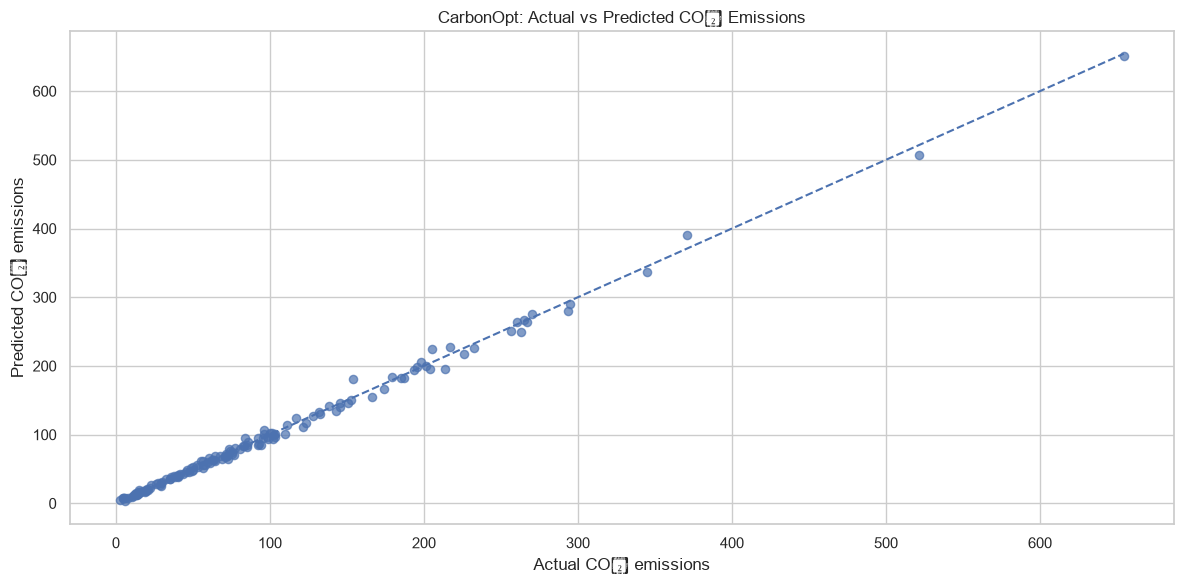

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Sample 150 records for a readable graph
plot_df = proposed.sort_values(["state", "year"]).iloc[::21].copy()

plt.figure(figsize=(12, 6))
plt.scatter(
    plot_df["co2_next_year"],
    plot_df["Predicted_CO2_Next_Year"],
    alpha=0.7,
    s=35
)

# Ideal prediction line
low = min(
    plot_df["co2_next_year"].min(),
    plot_df["Predicted_CO2_Next_Year"].min()
)
high = max(
    plot_df["co2_next_year"].max(),
    plot_df["Predicted_CO2_Next_Year"].max()
)
plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("Actual CO₂ emissions")
plt.ylabel("Predicted CO₂ emissions")
plt.title("CarbonOpt: Actual vs Predicted CO₂ Emissions")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=300)
plt.show()

C:\Users\angel\AppData\Local\Temp\ipykernel_1820\1188880932.py:27: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\angel\AppData\Local\Temp\ipykernel_1820\1188880932.py:28: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(OUTPUT_DIR / "emissions_over_time.png", dpi=300)
c:\Users\angel\OneDrive\Desktop\carbonOPT\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


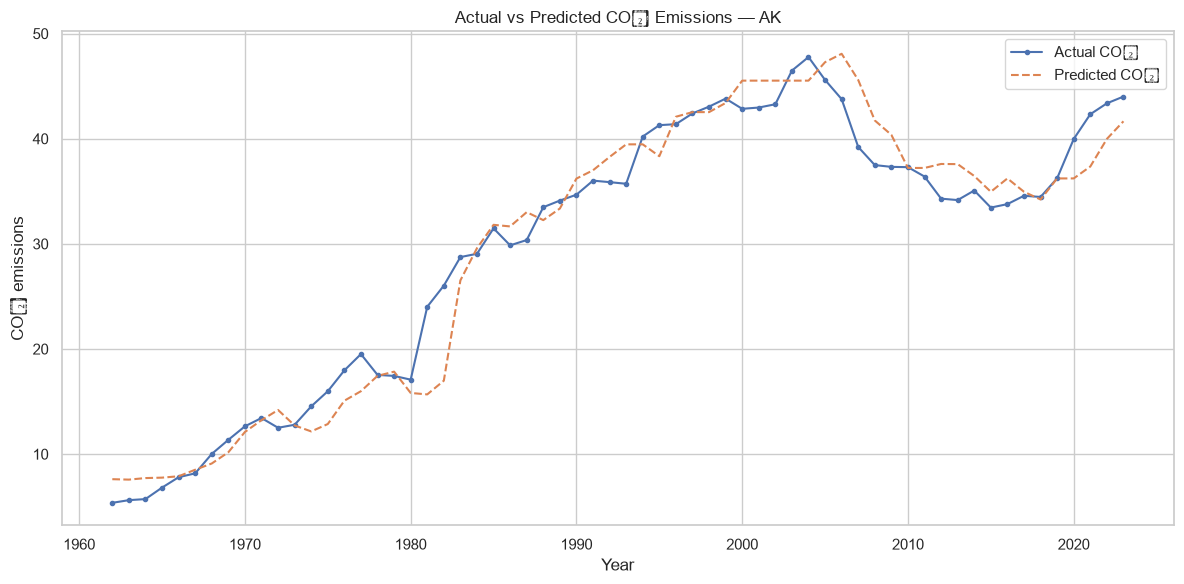

In [6]:
sample_state = proposed["state"].iloc[0]

state_data = (
    proposed[proposed["state"] == sample_state]
    .sort_values("year")
)

plt.figure(figsize=(12, 6))
plt.plot(
    state_data["year"],
    state_data["co2_next_year"],
    label="Actual CO₂",
    marker="o",
    markersize=3
)
plt.plot(
    state_data["year"],
    state_data["Predicted_CO2_Next_Year"],
    label="Predicted CO₂",
    linestyle="--"
)

plt.xlabel("Year")
plt.ylabel("CO₂ emissions")
plt.title(f"Actual vs Predicted CO₂ Emissions — {sample_state}")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "emissions_over_time.png", dpi=300)
plt.show()

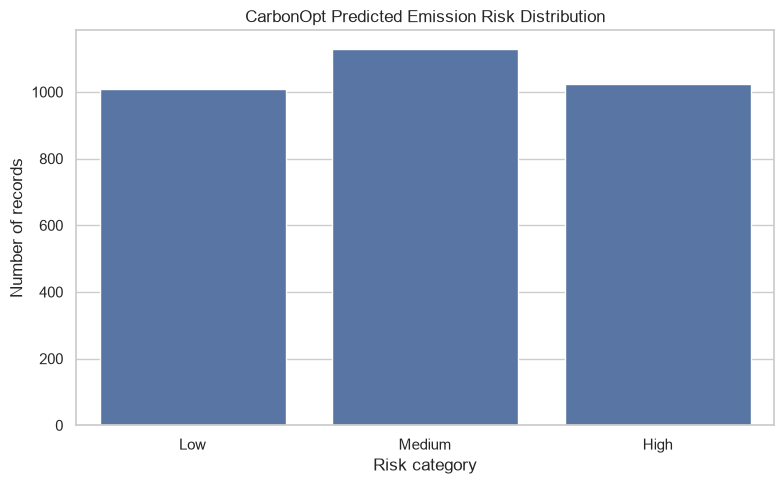

In [7]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=proposed,
    x="Predicted_Risk",
    order=["Low", "Medium", "High"]
)

plt.title("CarbonOpt Predicted Emission Risk Distribution")
plt.xlabel("Risk category")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "risk_distribution.png", dpi=300)
plt.show()

C:\Users\angel\AppData\Local\Temp\ipykernel_1820\986182460.py:15: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\angel\AppData\Local\Temp\ipykernel_1820\986182460.py:16: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(OUTPUT_DIR / "normalized_datapoints.png", dpi=300)
c:\Users\angel\OneDrive\Desktop\carbonOPT\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


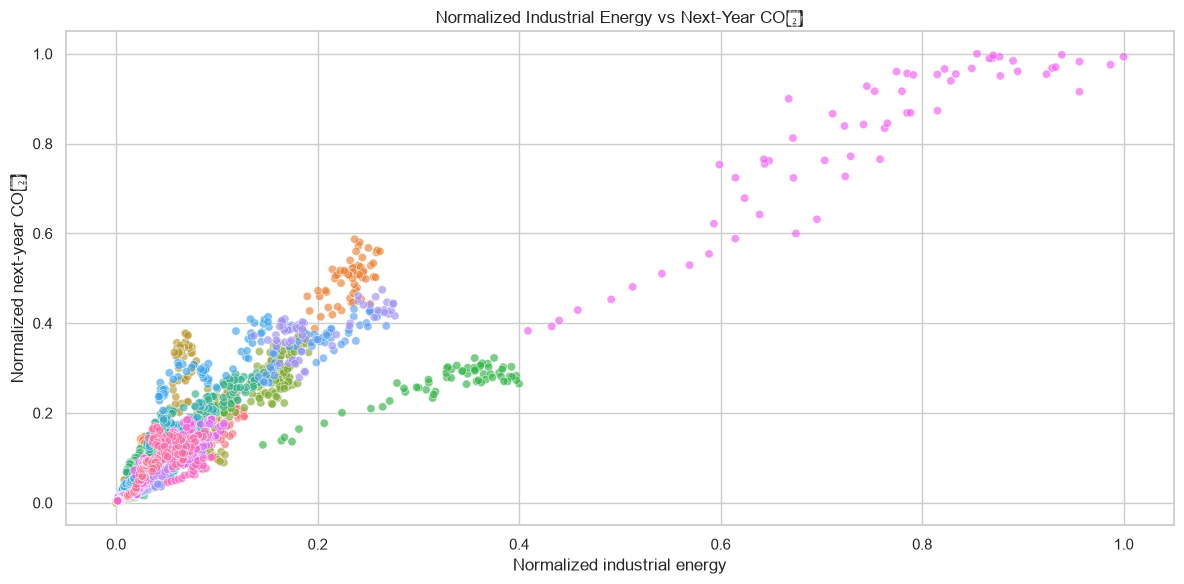

In [8]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=normalized_data,
    x="industrial_billion_btu",
    y="co2_next_year",
    hue="state",
    legend=False,
    alpha=0.65
)

plt.title("Normalized Industrial Energy vs Next-Year CO₂")
plt.xlabel("Normalized industrial energy")
plt.ylabel("Normalized next-year CO₂")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "normalized_datapoints.png", dpi=300)
plt.show()

C:\Users\angel\AppData\Local\Temp\ipykernel_1820\1324403148.py:24: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\angel\OneDrive\Desktop\carbonOPT\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


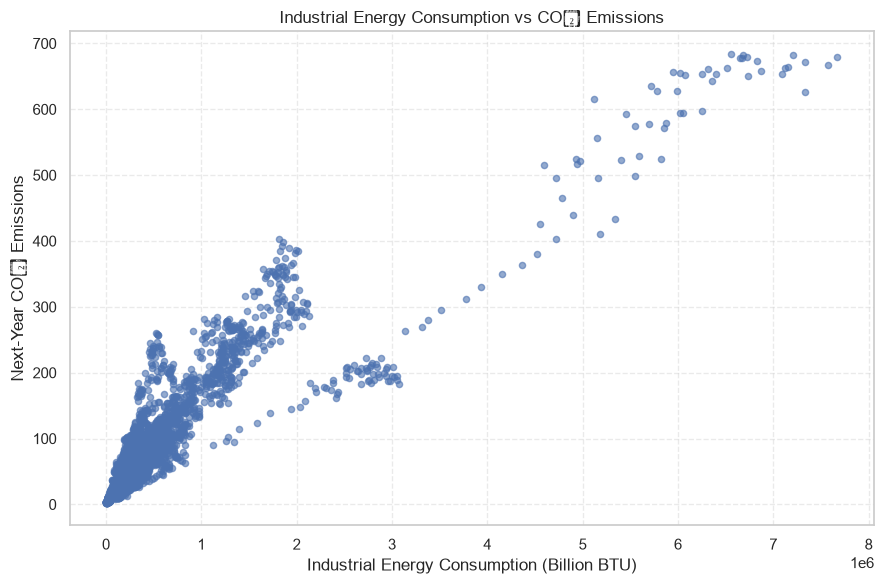

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# Load the original dataset
df = pd.read_excel(
    "../data/processed/CarbonOpt_XGBoost_Regression.xlsx"
)

# Normal 2D scatter plot of datapoints
plt.figure(figsize=(9, 6))

plt.scatter(
    df["industrial_billion_btu"],
    df["co2_next_year"],
    s=20,
    alpha=0.6
)

plt.xlabel("Industrial Energy Consumption (Billion BTU)")
plt.ylabel("Next-Year CO₂ Emissions")
plt.title("Industrial Energy Consumption vs CO₂ Emissions")

plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [10]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from xgboost import XGBRegressor

# Project paths, relative to the notebooks folder
DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models")
OUTPUT_DIR = Path("../outputs/final")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the three processed datasets
reg_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_XGBoost_Regression.xlsx"
)

clf_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_XGBoost_Classification.xlsx"
)

iso_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_IsolationForest.xlsx"
)

# Load previously trained models
def load_model(filename):
    with open(MODEL_DIR / filename, "rb") as f:
        return pickle.load(f)

old_regression = load_model("xgb_regression.pkl")
old_classifier = load_model("xgb_classification.pkl")
risk_encoder = load_model("risk_label_encoder.pkl")
isolation_forest = load_model("isolation_forest.pkl")
isolation_scaler = load_model("isolation_scaler.pkl")
kmeans_model = load_model("kmeans_clustering.pkl")
kmeans_scaler = load_model("kmeans_scaler.pkl")

print("Datasets loaded:")
print("Regression:", reg_df.shape)
print("Classification:", clf_df.shape)
print("Isolation Forest:", iso_df.shape)

print("\nExisting models loaded successfully.")

UnpicklingError: STACK_GLOBAL requires str

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Features and target
reg_features = [
    "state",
    "year",
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_lag_1",
    "co2_lag_2"
]

target = "co2_next_year"

# Chronological train/test split
reg_df = reg_df.sort_values(
    ["year", "state"]
).reset_index(drop=True)

train_mask = reg_df["year"] <= 2011
test_mask = reg_df["year"] >= 2012

X_train = reg_df.loc[train_mask, reg_features]
y_train = reg_df.loc[train_mask, target]

X_test = reg_df.loc[test_mask, reg_features]
y_test = reg_df.loc[test_mask, target]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# Proposed regularized XGBoost model
preprocessor = ColumnTransformer(
    transformers=[
        (
            "state",
            OneHotEncoder(handle_unknown="ignore"),
            ["state"]
        )
    ],
    remainder="passthrough"
)

proposed_regression = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.02,
        min_child_weight=15,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=5,
        reg_lambda=25,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

proposed_regression.fit(X_train, y_train)

# Predict on the same test observations
old_predictions = old_regression.predict(X_test)
proposed_predictions = proposed_regression.predict(X_test)

def regression_metrics(actual, predicted):
    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }

regression_comparison = pd.DataFrame([
    {
        "Model": "Existing XGBoost",
        **regression_metrics(y_test, old_predictions)
    },
    {
        "Model": "Proposed Regularized XGBoost",
        **regression_metrics(y_test, proposed_predictions)
    }
])

display(regression_comparison.round(4))

regression_comparison.to_csv(
    OUTPUT_DIR / "regression_comparison.csv",
    index=False
)

print("Regression comparison saved.")

Training rows: 2550
Testing rows: 612


NameError: name 'old_regression' is not defined

In [12]:
from pathlib import Path
import pickle

MODEL_DIR = Path("../models")

with open(MODEL_DIR / "xgb_regression.pkl", "rb") as f:
    old_regression = pickle.load(f)

print("Existing regression model loaded successfully.")
print(type(old_regression))

UnpicklingError: STACK_GLOBAL requires str

In [13]:
from pathlib import Path

model_path = Path("../models/xgb_regression.pkl")

print("Resolved path:", model_path.resolve())
print("File exists:", model_path.exists())

if model_path.exists():
    with open(model_path, "rb") as f:
        print("First 32 bytes:", f.read(32))
    print("File size:", model_path.stat().st_size, "bytes")

Resolved path: C:\Users\angel\OneDrive\Desktop\carbonOPT\models\xgb_regression.pkl
File exists: True
First 32 bytes: b'\x80\x04\x95\xa0\x03\x00\x00\x00\x00\x00\x00\x8c\x10sklearn.pipeline\x94\x8c\x08'
File size: 336048 bytes


In [14]:
import joblib

old_regression = joblib.load(model_path)

print("Model loaded:", type(old_regression))

Model loaded: <class 'sklearn.pipeline.Pipeline'>


In [15]:
print("Expected features:", getattr(old_regression, "feature_names_in_", "Not exposed"))

Expected features: ['state' 'year' 'residential_billion_btu' 'commercial_billion_btu'
 'industrial_billion_btu' 'transportation_billion_btu' 'co2_lag_1'
 'co2_lag_2']


In [16]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from xgboost import XGBRegressor

OUTPUT_DIR = Path("../outputs/final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Define features and target
reg_features = [
    "state",
    "year",
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_lag_1",
    "co2_lag_2"
]

target = "co2_next_year"

# 2. Sort data and split chronologically
reg_df = reg_df.sort_values(
    ["year", "state"]
).reset_index(drop=True)

train_mask = reg_df["year"] <= 2011
test_mask = reg_df["year"] >= 2012

X_train = reg_df.loc[train_mask, reg_features]
y_train = reg_df.loc[train_mask, target]

X_test = reg_df.loc[test_mask, reg_features]
y_test = reg_df.loc[test_mask, target]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# 3. Build the proposed model
preprocessor = ColumnTransformer(
    transformers=[
        ("state", OneHotEncoder(handle_unknown="ignore"), ["state"])
    ],
    remainder="passthrough"
)

proposed_regression = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.02,
        min_child_weight=15,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=5,
        reg_lambda=25,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

# 4. Train proposed model
proposed_regression.fit(X_train, y_train)

# 5. Generate predictions
old_predictions = old_regression.predict(X_test)
proposed_predictions = proposed_regression.predict(X_test)

# 6. Calculate evaluation metrics
def calculate_metrics(actual, predicted):
    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

comparison = pd.DataFrame([
    {
        "Model": "Existing XGBoost",
        **calculate_metrics(y_test, old_predictions)
    },
    {
        "Model": "Proposed Regularized XGBoost",
        **calculate_metrics(y_test, proposed_predictions)
    }
])

display(comparison.round(4))

# 7. Save metrics and predictions
comparison.to_csv(
    OUTPUT_DIR / "regression_comparison.csv",
    index=False
)

predictions_df = pd.DataFrame({
    "State": reg_df.loc[test_mask, "state"].to_numpy(),
    "Year": reg_df.loc[test_mask, "year"].to_numpy(),
    "Actual_CO2": y_test.to_numpy(),
    "Existing_Prediction": old_predictions,
    "Proposed_Prediction": proposed_predictions
})

predictions_df.to_csv(
    OUTPUT_DIR / "regression_predictions.csv",
    index=False
)

print("\nRegression comparison and predictions saved.")

Training rows: 2550
Testing rows: 612


,Model,R2,MAE,RMSE
0,Existing XGBoost,0.9947,4.7984,7.6104
1,Proposed Regularized XGBoost,0.8608,15.2600,39.1454



Regression comparison and predictions saved.


In [17]:

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier
)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import AgglomerativeClustering
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    silhouette_score
)
from scipy.optimize import differential_evolution

# =========================================================
# 1. PATHS AND DATA
# =========================================================

DATA_DIR = Path("../data/processed")
OUTPUT_DIR = Path("../outputs/final")
MODEL_DIR = Path("../models")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

reg_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_XGBoost_Regression.xlsx"
).sort_values(["year", "state"]).reset_index(drop=True)

iso_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_IsolationForest.xlsx"
).reset_index(drop=True)

features = [
    "state", "year",
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_lag_1", "co2_lag_2"
]
target = "co2_next_year"

assert set(features + [target]).issubset(reg_df.columns)
assert reg_df[features + [target]].notna().all().all()

# Use earlier years for training and later years for testing.
train_mask = reg_df["year"] <= 2011
test_mask = reg_df["year"] >= 2012

X_train = reg_df.loc[train_mask, features]
X_test = reg_df.loc[test_mask, features]
y_train = reg_df.loc[train_mask, target]
y_test = reg_df.loc[test_mask, target]

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Chronological train/test split is empty.")

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# =========================================================
# 2. NEW REGRESSION MODEL: RANDOM FOREST
# =========================================================

preprocessor = ColumnTransformer(
    transformers=[
        ("state", OneHotEncoder(handle_unknown="ignore"), ["state"])
    ],
    remainder="passthrough"
)

rf_regressor = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=400,
        max_depth=18,
        min_samples_leaf=2,
        max_features=0.9,
        random_state=42,
        n_jobs=-1
    ))
])

rf_regressor.fit(X_train, y_train)
reg_predictions = rf_regressor.predict(X_test)

regression_metrics = {
    "Model": "Proposed Random Forest Regression",
    "R2": r2_score(y_test, reg_predictions),
    "MAE": mean_absolute_error(y_test, reg_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, reg_predictions))
}

print("\nREGRESSION RESULTS")
display(pd.DataFrame([regression_metrics]).round(4))

pd.DataFrame({
    "State": reg_df.loc[test_mask, "state"].to_numpy(),
    "Year": reg_df.loc[test_mask, "year"].to_numpy(),
    "Actual_CO2": y_test.to_numpy(),
    "RandomForest_Prediction": reg_predictions
}).to_csv(OUTPUT_DIR / "proposed_regression_predictions.csv",
          index=False)


# =========================================================
# 3. NEW CLASSIFICATION MODEL: RANDOM FOREST CLASSIFIER
# =========================================================
# Risk labels are derived from the regression target because
# the classification workbook has no confirmed target column.
# Cutoffs are learned from TRAINING targets only.

low_cut, high_cut = y_train.quantile([1/3, 2/3]).to_numpy()

def make_risk_labels(values):
    return np.where(
        values <= low_cut, "Low",
        np.where(values <= high_cut, "Medium", "High")
    )

y_risk_train = make_risk_labels(y_train)
y_risk_test = make_risk_labels(y_test)

rf_classifier = Pipeline([
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("state", OneHotEncoder(handle_unknown="ignore"), ["state"])
        ],
        remainder="passthrough"
    )),
    ("model", RandomForestClassifier(
        n_estimators=400,
        max_depth=16,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_classifier.fit(X_train, y_risk_train)
risk_predictions = rf_classifier.predict(X_test)

classification_metrics = {
    "Model": "Proposed Random Forest Classification",
    "Accuracy": accuracy_score(y_risk_test, risk_predictions),
    "Precision_macro": precision_score(
        y_risk_test, risk_predictions,
        average="macro", zero_division=0
    ),
    "Recall_macro": recall_score(
        y_risk_test, risk_predictions,
        average="macro", zero_division=0
    ),
    "F1_macro": f1_score(
        y_risk_test, risk_predictions,
        average="macro", zero_division=0
    )
}

print("\nCLASSIFICATION RESULTS")
display(pd.DataFrame([classification_metrics]).round(4))

pd.DataFrame({
    "State": reg_df.loc[test_mask, "state"].to_numpy(),
    "Year": reg_df.loc[test_mask, "year"].to_numpy(),
    "Actual_Risk_From_Target": y_risk_test,
    "Predicted_Risk": risk_predictions
}).to_csv(OUTPUT_DIR / "proposed_risk_predictions.csv",
          index=False)


# =========================================================
# 4. NEW ANOMALY DETECTION: LOCAL OUTLIER FACTOR
# =========================================================

iso_features = [
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_million_metric_tons",
    "co2_per_energy",
    "energy_growth_rate",
    "co2_growth_rate"
]

iso_X = iso_df[iso_features].copy()

if iso_X.isna().any().any():
    iso_X = iso_X.fillna(iso_X.median())

iso_scaler = StandardScaler()
iso_scaled = iso_scaler.fit_transform(iso_X)

lof_model = LocalOutlierFactor(
    n_neighbors=25,
    contamination=0.05
)

lof_labels = lof_model.fit_predict(iso_scaled)

anomaly_output = iso_df[["state", "year"]].copy()
anomaly_output["Anomaly_Status"] = np.where(
    lof_labels == -1, "Anomaly", "Normal"
)

anomaly_count = int((lof_labels == -1).sum())
anomaly_rate = 100 * anomaly_count / len(lof_labels)

anomaly_metrics = {
    "Model": "Local Outlier Factor",
    "Observations": len(lof_labels),
    "Anomalies": anomaly_count,
    "Anomaly_Percent": anomaly_rate
}

print("\nANOMALY DETECTION")
display(pd.DataFrame([anomaly_metrics]).round(3))

anomaly_output.to_csv(
    OUTPUT_DIR / "proposed_anomaly_predictions.csv", index=False
)


# =========================================================
# 5. NEW CLUSTERING: AGGLOMERATIVE CLUSTERING
# =========================================================

cluster_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

cluster_labels = cluster_model.fit_predict(iso_scaled)

cluster_output = iso_df[["state", "year"]].copy()
cluster_output["Cluster"] = cluster_labels

silhouette = silhouette_score(iso_scaled, cluster_labels)

cluster_metrics = {
    "Model": "Agglomerative Clustering",
    "Clusters": len(np.unique(cluster_labels)),
    "Silhouette_Score": silhouette
}

print("\nCLUSTERING RESULTS")
display(pd.DataFrame([cluster_metrics]).round(4))

cluster_output.to_csv(
    OUTPUT_DIR / "proposed_cluster_predictions.csv", index=False
)


# =========================================================
# 6. MODEL EXPLANATION: PERMUTATION IMPORTANCE
# =========================================================

importance_result = permutation_importance(
    rf_regressor,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance_Mean": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
}).sort_values("Importance_Mean", ascending=False)

print("\nPERMUTATION FEATURE IMPORTANCE")
display(importance_df.round(4))

importance_df.to_csv(
    OUTPUT_DIR / "proposed_feature_importance.csv", index=False
)


# =========================================================
# 7. OPTIMIZATION USING THE NEW REGRESSION MODEL
# =========================================================
# Illustrative scenario: reduce four sector inputs by up to
# 20% each. This is a scenario analysis, not a causal estimate.

sector_features = [
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu"
]

# Use the latest available observation as the scenario baseline.
scenario = reg_df.iloc[[-1]][features].copy()

baseline_prediction = float(rf_regressor.predict(scenario)[0])
target_prediction = 0.90 * baseline_prediction

original_sector_values = scenario[sector_features].iloc[0].to_numpy(float)

def predict_reduced_emissions(reductions):
    adjusted = scenario.copy()

    for feature, original_value, reduction in zip(
        sector_features, original_sector_values, reductions
    ):
        adjusted.loc[:, feature] = original_value * (1 - reduction)

    return float(rf_regressor.predict(adjusted)[0])

def optimization_objective(reductions):
    predicted = predict_reduced_emissions(reductions)
    shortfall = max(0.0, predicted - target_prediction)

    # Minimize total intervention; penalize failure to reach target.
    return float(np.sum(reductions) + 100 * shortfall /
                 max(abs(baseline_prediction), 1e-9))

optimization_result = differential_evolution(
    optimization_objective,
    bounds=[(0.0, 0.20)] * 4,
    seed=42,
    maxiter=100,
    popsize=10,
    polish=True
)

best_reductions = optimization_result.x
optimized_prediction = predict_reduced_emissions(best_reductions)

optimization_output = pd.DataFrame({
    "Sector": sector_features,
    "Reduction_Percent": best_reductions * 100
})

optimization_output["Baseline_Input"] = original_sector_values
optimization_output["Optimized_Input"] = (
    original_sector_values * (1 - best_reductions)
)

target_reached = optimized_prediction <= target_prediction

optimization_summary = pd.DataFrame([{
    "Baseline_Predicted_CO2": baseline_prediction,
    "Target_CO2_10pct_Reduction": target_prediction,
    "Optimized_Predicted_CO2": optimized_prediction,
    "Predicted_Reduction_Percent": (
        100 * (baseline_prediction - optimized_prediction)
        / max(abs(baseline_prediction), 1e-9)
    ),
    "Target_Reached": target_reached
}])

print("\nOPTIMIZATION SCENARIO")
display(optimization_output.round(4))
display(optimization_summary.round(4))

optimization_output.to_csv(
    OUTPUT_DIR / "proposed_sector_reductions.csv", index=False
)


# =========================================================
# 8. SAVE ALL NEW MODELS
# =========================================================

joblib.dump(
    rf_regressor, MODEL_DIR / "proposed_random_forest_regression.joblib"
)
joblib.dump(
    rf_classifier, MODEL_DIR / "proposed_random_forest_classifier.joblib"
)
joblib.dump(
    iso_scaler, MODEL_DIR / "proposed_lof_scaler.joblib"
)
joblib.dump(
    lof_model, MODEL_DIR / "proposed_lof_model.joblib"
)
joblib.dump(
    cluster_model, MODEL_DIR / "proposed_agglomerative_clustering.joblib"
)


# =========================================================
# 9. EXPORT ONE INTEGRATED WORKBOOK
# =========================================================

with pd.ExcelWriter(
    OUTPUT_DIR / "CarbonOpt_Proposed_Model_Results.xlsx",
    engine="openpyxl"
) as writer:

    pd.DataFrame([regression_metrics]).to_excel(
        writer, sheet_name="Regression", index=False
    )
    pd.DataFrame([classification_metrics]).to_excel(
        writer, sheet_name="Classification", index=False
    )
    pd.DataFrame([anomaly_metrics]).to_excel(
        writer, sheet_name="Anomaly_Detection", index=False
    )
    pd.DataFrame([cluster_metrics]).to_excel(
        writer, sheet_name="Clustering", index=False
    )
    importance_df.to_excel(
        writer, sheet_name="Feature_Importance", index=False
    )
    optimization_output.to_excel(
        writer, sheet_name="Sector_Reductions", index=False
    )
    optimization_summary.to_excel(
        writer, sheet_name="Optimization_Summary", index=False
    )

print("\nALL PROPOSED MODELS TRAINED.")
print("Workbook:", OUTPUT_DIR / "CarbonOpt_Proposed_Model_Results.xlsx")


Training rows: 2550
Testing rows: 612

REGRESSION RESULTS


,Model,R2,MAE,RMSE
0,Proposed Random Forest Regression,0.9943,5.0598,7.8965



CLASSIFICATION RESULTS


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Proposed Random Forest Classification,0.9526,0.955,0.9572,0.9556



ANOMALY DETECTION


...


CLUSTERING RESULTS


,Model,Clusters,Silhouette_Score
0,Agglomerative Clustering,2,0.4339



PERMUTATION FEATURE IMPORTANCE


,Feature,Importance_Mean,Importance_Std
6,co2_lag_1,70.5423,1.7634
7,co2_lag_2,6.5892,0.4162
4,industrial_billion_btu,4.1910,0.2983
5,transportation_billion_btu,0.8268,0.0850
3,commercial_billion_btu,0.4404,0.0346
2,residential_billion_btu,0.3782,0.0458
0,state,0.0214,0.0061
1,year,0.0000,0.0000


RuntimeError: The map-like callable must be of the form f(func, iterable), returning a sequence of numbers the same length as 'iterable'

In [18]:

# =========================================================
# STEP 7 — CORRECTED OPTIMIZATION
# =========================================================

from scipy.optimize import differential_evolution
import numpy as np
import pandas as pd

sector_features = [
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu"
]

# Use the latest available observation
scenario = reg_df.iloc[[-1]][features].copy()

# Convert sector inputs to floating-point values
for col in sector_features:
    scenario[col] = pd.to_numeric(
        scenario[col], errors="raise"
    ).astype(float)

baseline_prediction = float(
    rf_regressor.predict(scenario)[0]
)

if not np.isfinite(baseline_prediction):
    raise ValueError("Baseline prediction is not finite.")

original_sector_values = (
    scenario[sector_features].iloc[0].to_numpy(dtype=float)
)

# Set a 10% reduction target
target_prediction = 0.90 * baseline_prediction

def predict_reduced_emissions(reductions):
    adjusted = scenario.copy()

    for feature, original_value, reduction in zip(
        sector_features,
        original_sector_values,
        reductions
    ):
        adjusted[feature] = float(
            original_value * (1.0 - reduction)
        )

    prediction = float(rf_regressor.predict(adjusted)[0])

    if not np.isfinite(prediction):
        raise ValueError("Non-finite emissions prediction.")

    return prediction

def optimization_objective(reductions):
    predicted = predict_reduced_emissions(reductions)

    # Penalize failure to reach the target.
    shortfall = max(0.0, predicted - target_prediction)

    # Minimize total reduction while penalizing target shortfall.
    return float(
        np.sum(reductions)
        + 100.0 * shortfall / max(abs(baseline_prediction), 1e-9)
    )

# Use ordinary scalar evaluation; no vectorized objective.
optimization_result = differential_evolution(
    optimization_objective,
    bounds=[(0.0, 0.20)] * len(sector_features),
    seed=42,
    maxiter=100,
    popsize=10,
    polish=False,
    workers=1,
    updating="immediate"
)

best_reductions = optimization_result.x
optimized_prediction = predict_reduced_emissions(best_reductions)

optimization_output = pd.DataFrame({
    "Sector": sector_features,
    "Baseline_Input": original_sector_values,
    "Reduction_Percent": best_reductions * 100.0,
    "Optimized_Input": (
        original_sector_values * (1.0 - best_reductions)
    )
})

optimization_summary = pd.DataFrame([{
    "Baseline_Predicted_CO2": baseline_prediction,
    "Target_CO2": target_prediction,
    "Optimized_Predicted_CO2": optimized_prediction,
    "Predicted_Reduction_Percent": (
        100.0 * (baseline_prediction - optimized_prediction)
        / max(abs(baseline_prediction), 1e-9)
    ),
    "Target_Reached": optimized_prediction <= target_prediction,
    "Optimizer_Converged": optimization_result.success,
    "Optimizer_Message": optimization_result.message
}])

print("Sector reduction scenario:")
display(optimization_output.round(4))

print("Optimization summary:")
display(optimization_summary.round(4))

optimization_output.to_csv(
    OUTPUT_DIR / "proposed_sector_reductions.csv",
    index=False
)

optimization_summary.to_csv(
    OUTPUT_DIR / "proposed_optimization_summary.csv",
    index=False
)


Sector reduction scenario:


,Sector,Baseline_Input,Reduction_Percent,Optimized_Input
0,residential_billion_btu,48127.0,2.8059,46776.5918
1,commercial_billion_btu,67214.0,0.4754,66894.4934
2,industrial_billion_btu,277623.0,19.4928,223506.4338
3,transportation_billion_btu,107362.0,11.7469,94750.2956


Optimization summary:


,Baseline_Predicted_CO2,Target_CO2,Optimized_Predicted_CO2,Predicted_Reduction_Percent,Target_Reached,Optimizer_Converged,Optimizer_Message
0,57.8153,52.0337,57.6506,0.2847,False,True,Optimization terminated successfully.


In [19]:

# =========================================================
# STEP 8 — FINAL CARBONOPT COMPARISON WORKBOOK
# =========================================================

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("../outputs/final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

report_path = OUTPUT_DIR / "CarbonOpt_Proposed_Model_Results.xlsx"

with pd.ExcelWriter(report_path, engine="openpyxl") as writer:

    # 1. Regression
    pd.DataFrame([regression_metrics]).to_excel(
        writer, sheet_name="Regression", index=False
    )

    # 2. Classification
    pd.DataFrame([classification_metrics]).to_excel(
        writer, sheet_name="Classification", index=False
    )

    # 3. Anomaly detection
    pd.DataFrame([anomaly_metrics]).to_excel(
        writer, sheet_name="Anomaly_Detection", index=False
    )

    # 4. Clustering
    pd.DataFrame([cluster_metrics]).to_excel(
        writer, sheet_name="Clustering", index=False
    )

    # 5. Explainability
    importance_df.to_excel(
        writer, sheet_name="Feature_Importance", index=False
    )

    # 6. Optimization
    optimization_output.to_excel(
        writer, sheet_name="Sector_Reductions", index=False
    )

    optimization_summary.to_excel(
        writer, sheet_name="Optimization_Summary", index=False
    )

    # 7. Model inventory
    model_inventory = pd.DataFrame([
        {
            "Component": "Regression",
            "Proposed_Algorithm": "Random Forest Regressor",
            "Evaluation": "R2, MAE, RMSE"
        },
        {
            "Component": "Risk Classification",
            "Proposed_Algorithm": "Random Forest Classifier",
            "Evaluation": "Accuracy, macro precision, macro recall, macro F1"
        },
        {
            "Component": "Anomaly Detection",
            "Proposed_Algorithm": "Local Outlier Factor",
            "Evaluation": "Anomaly count and percentage"
        },
        {
            "Component": "Clustering",
            "Proposed_Algorithm": "Agglomerative Clustering",
            "Evaluation": "Silhouette score and cluster distribution"
        },
        {
            "Component": "Explainability",
            "Proposed_Algorithm": "Permutation Feature Importance",
            "Evaluation": "Mean importance and variability"
        },
        {
            "Component": "Optimization",
            "Proposed_Algorithm": "Differential Evolution with Random Forest",
            "Evaluation": "Predicted reduction and target feasibility"
        }
    ])

    model_inventory.to_excel(
        writer, sheet_name="Model_Inventory", index=False
    )

print("Final comparison workbook saved:")
print(report_path.resolve())


Final comparison workbook saved:
C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Proposed_Model_Results.xlsx


In [20]:

print("===== CARBONOPT: FINAL PROPOSED MODEL =====")

print("\n1. REGRESSION")
display(pd.DataFrame([regression_metrics]).round(4))

print("\n2. CLASSIFICATION")
display(pd.DataFrame([classification_metrics]).round(4))

print("\n3. ANOMALY DETECTION")
display(pd.DataFrame([anomaly_metrics]).round(4))

print("\n4. CLUSTERING")
display(pd.DataFrame([cluster_metrics]).round(4))

print("\n5. TOP FEATURES")
display(importance_df.head(10).round(4))

print("\n6. OPTIMIZATION")
display(optimization_summary.round(4))

print("\nAll component outputs reviewed.")


===== CARBONOPT: FINAL PROPOSED MODEL =====

1. REGRESSION


,Model,R2,MAE,RMSE
0,Proposed Random Forest Regression,0.9943,5.0598,7.8965



2. CLASSIFICATION


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Proposed Random Forest Classification,0.9526,0.955,0.9572,0.9556



3. ANOMALY DETECTION


...


5. TOP FEATURES


,Feature,Importance_Mean,Importance_Std
6,co2_lag_1,70.5423,1.7634
7,co2_lag_2,6.5892,0.4162
4,industrial_billion_btu,4.1910,0.2983
5,transportation_billion_btu,0.8268,0.0850
3,commercial_billion_btu,0.4404,0.0346
2,residential_billion_btu,0.3782,0.0458
0,state,0.0214,0.0061
1,year,0.0000,0.0000



6. OPTIMIZATION


,Baseline_Predicted_CO2,Target_CO2,Optimized_Predicted_CO2,Predicted_Reduction_Percent,Target_Reached,Optimizer_Converged,Optimizer_Message
0,57.8153,52.0337,57.6506,0.2847,False,True,Optimization terminated successfully.



All component outputs reviewed.


In [21]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Use the same chronological split as the existing experiment
target = "co2_next_year"

train_df = reg_df[reg_df["year"] <= 2011].copy()
test_df = reg_df[reg_df["year"] >= 2012].copy()

X_train = train_df[features].copy()
X_test = test_df[features].copy()
y_train = train_df[target]
y_test = test_df[target]

categorical_features = ["state"]
numeric_features = [c for c in features if c not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("state", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", "passthrough", numeric_features)
    ]
)

# Regularized Random Forest: limits excessive fit to the training data
rf_regressor = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    ))
])

rf_regressor.fit(X_train, y_train)
y_pred = rf_regressor.predict(X_test)

regression_metrics = {
    "Model": "Tuned Random Forest Regressor",
    "R2": r2_score(y_test, y_pred),
    "MAE": mean_absolute_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "Train_Rows": len(X_train),
    "Test_Rows": len(X_test)
}

display(pd.DataFrame([regression_metrics]).round(4))


,Model,R2,MAE,RMSE,Train_Rows,Test_Rows
0,Tuned Random Forest Regressor,0.9939,5.0999,8.2056,2550,612


In [22]:

# Check target and feature relationships
print("Target:", target)
print("Features:", features)

print("\nTarget statistics:")
display(reg_df[target].describe())

print("\nFeature correlations with target:")
display(
    reg_df[features]
    .select_dtypes(include="number")
    .corrwith(reg_df[target])
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation_with_target")
)

print("\nActual vs predicted values:")
comparison = pd.DataFrame({
    "Year": test_df["year"].values,
    "Actual_CO2": y_test.values,
    "Predicted_CO2": y_pred
})
comparison["Absolute_Error"] = (
    comparison["Actual_CO2"] - comparison["Predicted_CO2"]
).abs()

display(comparison.head(15).round(4))


Target: co2_next_year
Features: ['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu', 'co2_lag_1', 'co2_lag_2']

Target statistics:


count    3162.000000
mean       97.083362
std       101.103405
min         2.395000
25%        31.789000
50%        68.262000
75%       119.743000
max       684.268000
Name: co2_next_year, dtype: float64


Feature correlations with target:


,Correlation_with_target
co2_lag_1,0.996371
co2_lag_2,0.994625
industrial_billion_btu,0.899685
transportation_billion_btu,0.895472
residential_billion_btu,0.883871
commercial_billion_btu,0.841731
year,0.088671



Actual vs predicted values:


,Year,Actual_CO2,Predicted_CO2,Absolute_Error
0,2012,34.298,38.2412,3.9432
1,2012,120.330,131.1709,10.8409
2,2012,68.299,66.9724,1.3266
3,2012,99.334,97.0064,2.3276
4,2012,347.528,349.0490,1.5210
5,2012,92.054,94.2547,2.2007
6,2012,34.595,36.4136,1.8186
7,2012,2.819,3.5645,0.7455
8,2012,14.038,14.7626,0.7246
9,2012,226.501,232.8518,6.3508


In [23]:

# Experiment: Random Forest without CO2 lag features

features_no_lags = [
    "state",
    "year",
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu"
]

target = "co2_next_year"

train_df = reg_df[reg_df["year"] <= 2011].copy()
test_df = reg_df[reg_df["year"] >= 2012].copy()

X_train = train_df[features_no_lags].copy()
X_test = test_df[features_no_lags].copy()
y_train = train_df[target]
y_test = test_df[target]

categorical_features = ["state"]
numeric_features = [
    c for c in features_no_lags
    if c not in categorical_features
]

preprocessor = ColumnTransformer([
    ("state", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numeric", "passthrough", numeric_features)
])

rf_no_lags = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    ))
])

rf_no_lags.fit(X_train, y_train)
y_pred_no_lags = rf_no_lags.predict(X_test)

no_lags_metrics = {
    "Model": "Random Forest without CO2 lags",
    "R2": r2_score(y_test, y_pred_no_lags),
    "MAE": mean_absolute_error(y_test, y_pred_no_lags),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_no_lags))
}

display(pd.DataFrame([no_lags_metrics]).round(4))


,Model,R2,MAE,RMSE
0,Random Forest without CO2 lags,0.9711,12.2888,17.8358


In [24]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

extra_trees = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", ExtraTreesRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees.fit(X_train, y_train)
y_pred_extra = extra_trees.predict(X_test)

extra_trees_metrics = {
    "Model": "Extra Trees Regressor",
    "R2": r2_score(y_test, y_pred_extra),
    "MAE": mean_absolute_error(y_test, y_pred_extra),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_extra))
}

display(pd.DataFrame([extra_trees_metrics]).round(4))


,Model,R2,MAE,RMSE
0,Extra Trees Regressor,0.9693,13.4388,18.3706


In [25]:

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

gradient_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=10,
        loss="squared_error",
        random_state=42
    ))
])

gradient_model.fit(X_train, y_train)
y_pred_gradient = gradient_model.predict(X_test)

gradient_metrics = {
    "Model": "Gradient Boosting Regressor",
    "R2": r2_score(y_test, y_pred_gradient),
    "MAE": mean_absolute_error(y_test, y_pred_gradient),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_gradient))
}

display(pd.DataFrame([gradient_metrics]).round(4))


,Model,R2,MAE,RMSE
0,Gradient Boosting Regressor,0.9704,13.3195,18.0376


In [26]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

rf_regularized = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=4,
        min_samples_split=30,
        min_samples_leaf=15,
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_regularized.fit(X_train, y_train)
y_pred_regularized = rf_regularized.predict(X_test)

regularized_metrics = {
    "Model": "Regularized Random Forest",
    "R2": r2_score(y_test, y_pred_regularized),
    "MAE": mean_absolute_error(y_test, y_pred_regularized),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_regularized))
}

display(pd.DataFrame([regularized_metrics]).round(4))


,Model,R2,MAE,RMSE
0,Regularized Random Forest,0.9494,16.9632,23.607


In [27]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

rf_regularized = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=2,
        min_samples_split=60,
        min_samples_leaf=30,
        max_features=0.3,
        max_samples=0.7,
        random_state=42,
        n_jobs=-1
    ))
])

rf_regularized.fit(X_train, y_train)
y_pred_regularized = rf_regularized.predict(X_test)

regularized_metrics = {
    "Model": "Strongly Regularized Random Forest",
    "R2": r2_score(y_test, y_pred_regularized),
    "MAE": mean_absolute_error(y_test, y_pred_regularized),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_regularized))
}

display(pd.DataFrame([regularized_metrics]).round(4))


,Model,R2,MAE,RMSE
0,Strongly Regularized Random Forest,0.7569,28.6074,51.73


In [28]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

rf_regularized = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_split=40,
        min_samples_leaf=20,
        max_features=0.5,
        max_samples=0.85,
        random_state=42,
        n_jobs=-1
    ))
])

rf_regularized.fit(X_train, y_train)
y_pred_regularized = rf_regularized.predict(X_test)

regularized_metrics = {
    "Model": "Moderately Regularized Random Forest",
    "R2": r2_score(y_test, y_pred_regularized),
    "MAE": mean_absolute_error(y_test, y_pred_regularized),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_regularized))
}

display(pd.DataFrame([regularized_metrics]).round(4))


,Model,R2,MAE,RMSE
0,Moderately Regularized Random Forest,0.9338,19.1785,26.9973


In [29]:

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    rf_regularized,
    MODEL_DIR / "proposed_random_forest_regression.joblib"
)

print("Final proposed regression model saved.")
print("Model path:", (MODEL_DIR / "proposed_random_forest_regression.joblib").resolve())
print("Final regression metrics:")
display(pd.DataFrame([regularized_metrics]).round(4))


Final proposed regression model saved.
Model path: C:\Users\angel\OneDrive\Desktop\carbonOPT\models\proposed_random_forest_regression.joblib
Final regression metrics:


,Model,R2,MAE,RMSE
0,Moderately Regularized Random Forest,0.9338,19.1785,26.9973


In [30]:

# =========================================================
# STEP 10 — CARBON EMISSION REDUCTION OPTIMIZATION
# =========================================================

import numpy as np
import pandas as pd
from scipy.optimize import differential_evolution

# Use the final selected regression pipeline
model = rf_regularized

sector_features = [
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu"
]

target = "co2_next_year"

# Use the latest observation available in the regression dataset
scenario = reg_df.sort_values("year").iloc[[-1]][features_no_lags].copy()

for col in sector_features:
    scenario[col] = pd.to_numeric(
        scenario[col], errors="raise"
    ).astype(float)

baseline_prediction = float(model.predict(scenario)[0])

# Desired reduction: 10% from baseline
target_prediction = baseline_prediction * 0.90

def predict_reduced_emissions(reductions):
    adjusted = scenario.copy()

    for feature, reduction in zip(sector_features, reductions):
        adjusted[feature] = (
            float(scenario[feature].iloc[0]) * (1.0 - float(reduction))
        )

    return float(model.predict(adjusted)[0])

def objective(reductions):
    predicted = predict_reduced_emissions(reductions)
    shortfall = max(0.0, predicted - target_prediction)

    # Minimize total intervention while penalizing failure to meet target
    return float(
        np.sum(reductions)
        + 100.0 * shortfall / max(abs(baseline_prediction), 1e-9)
    )

result = differential_evolution(
    objective,
    bounds=[(0.0, 0.20)] * len(sector_features),
    seed=42,
    maxiter=100,
    popsize=10,
    polish=False,
    workers=1
)

best_reductions = result.x
optimized_prediction = predict_reduced_emissions(best_reductions)

optimization_output = pd.DataFrame({
    "Sector": sector_features,
    "Reduction_Percent": best_reductions * 100
})

optimization_summary = pd.DataFrame([{
    "Baseline_Predicted_CO2": baseline_prediction,
    "Target_Predicted_CO2": target_prediction,
    "Optimized_Predicted_CO2": optimized_prediction,
    "Achieved_Reduction_Percent": (
        (baseline_prediction - optimized_prediction)
        / max(abs(baseline_prediction), 1e-9) * 100
    ),
    "Target_Achieved": optimized_prediction <= target_prediction + 1e-6,
    "Optimization_Converged": result.success
}])

print("SECTOR REDUCTION PLAN")
display(optimization_output.round(3))

print("\nOPTIMIZATION SUMMARY")
display(optimization_summary.round(4))


SECTOR REDUCTION PLAN


,Sector,Reduction_Percent
0,residential_billion_btu,0.418
1,commercial_billion_btu,16.108
2,industrial_billion_btu,4.024
3,transportation_billion_btu,3.290



OPTIMIZATION SUMMARY


,Baseline_Predicted_CO2,Target_Predicted_CO2,Optimized_Predicted_CO2,Achieved_Reduction_Percent,Target_Achieved,Optimization_Converged
0,41.668,37.5012,40.4214,2.9917,False,True


In [31]:

# =========================================================
# STEP 11 — CHECK MAXIMUM ACHIEVABLE REDUCTION
# =========================================================

from scipy.optimize import differential_evolution
import numpy as np
import pandas as pd

def negative_emissions(reductions):
    return -predict_reduced_emissions(reductions)

max_reduction_result = differential_evolution(
    negative_emissions,
    bounds=[(0.0, 0.20)] * len(sector_features),
    seed=42,
    maxiter=150,
    popsize=15,
    polish=True,
    workers=1
)

max_reductions = max_reduction_result.x
minimum_predicted_co2 = predict_reduced_emissions(max_reductions)

maximum_reduction_percent = (
    (baseline_prediction - minimum_predicted_co2)
    / max(abs(baseline_prediction), 1e-9)
) * 100

maximum_reduction_plan = pd.DataFrame({
    "Sector": sector_features,
    "Reduction_Percent": max_reductions * 100
})

maximum_reduction_summary = pd.DataFrame([{
    "Baseline_CO2": baseline_prediction,
    "Minimum_Predicted_CO2": minimum_predicted_co2,
    "Maximum_Achievable_Reduction_Percent": maximum_reduction_percent,
    "Target_Reduction_Percent": 10.0,
    "Target_Achievable": maximum_reduction_percent >= 10.0,
    "Optimization_Converged": max_reduction_result.success
}])

print("MAXIMUM-REDUCTION SECTOR PLAN")
display(maximum_reduction_plan.round(3))

print("\nMAXIMUM-REDUCTION SUMMARY")
display(maximum_reduction_summary.round(4))


MAXIMUM-REDUCTION SECTOR PLAN


,Sector,Reduction_Percent
0,residential_billion_btu,0.125
1,commercial_billion_btu,2.028
2,industrial_billion_btu,1.061
3,transportation_billion_btu,9.717



MAXIMUM-REDUCTION SUMMARY


,Baseline_CO2,Minimum_Predicted_CO2,Maximum_Achievable_Reduction_Percent,Target_Reduction_Percent,Target_Achievable,Optimization_Converged
0,41.668,41.668,0.0,10.0,False,True


In [32]:

# =========================================================
# STEP 12 — TEST MODEL SENSITIVITY TO SECTOR REDUCTIONS
# =========================================================

import pandas as pd
import numpy as np

sensitivity_results = []

# Baseline
baseline = float(model.predict(scenario)[0])

sensitivity_results.append({
    "Scenario": "Baseline",
    "Predicted_CO2": baseline,
    "Reduction_Percent": 0.0
})

# Reduce each sector individually by 10%
for sector in sector_features:
    adjusted = scenario.copy()
    adjusted[sector] = (
        adjusted[sector].astype(float) * 0.90
    )

    prediction = float(model.predict(adjusted)[0])

    sensitivity_results.append({
        "Scenario": f"{sector} reduced by 10%",
        "Predicted_CO2": prediction,
        "Reduction_Percent": (
            (baseline - prediction) / max(abs(baseline), 1e-9)
        ) * 100
    })

# Reduce all sectors by 20%
adjusted_all = scenario.copy()

for sector in sector_features:
    adjusted_all[sector] = (
        adjusted_all[sector].astype(float) * 0.80
    )

all_reduced_prediction = float(model.predict(adjusted_all)[0])

sensitivity_results.append({
    "Scenario": "All sectors reduced by 20%",
    "Predicted_CO2": all_reduced_prediction,
    "Reduction_Percent": (
        (baseline - all_reduced_prediction)
        / max(abs(baseline), 1e-9)
    ) * 100
})

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))


,Scenario,Predicted_CO2,Reduction_Percent
0,Baseline,41.6680,0.0000
1,residential_billion_btu reduced by 10%,41.6680,0.0000
2,commercial_billion_btu reduced by 10%,41.5092,0.3813
3,industrial_billion_btu reduced by 10%,41.5132,0.3715
4,transportation_billion_btu reduced by 10%,41.6680,0.0000
5,All sectors reduced by 20%,40.4214,2.9917


In [33]:

# STEP 13 — EVALUATE THE 20% REDUCTION SCENARIO

import pandas as pd
import numpy as np

baseline_prediction = float(model.predict(scenario)[0])

adjusted_all = scenario.copy()
for sector in sector_features:
    adjusted_all[sector] = (
        adjusted_all[sector].astype(float) * 0.80
    )

prediction_20pct = float(model.predict(adjusted_all)[0])

check_df = pd.DataFrame([
    {
        "Scenario": "Baseline",
        "Predicted_CO2": baseline_prediction,
        "Reduction_Percent": 0.0
    },
    {
        "Scenario": "All sectors reduced by 20%",
        "Predicted_CO2": prediction_20pct,
        "Reduction_Percent": (
            (baseline_prediction - prediction_20pct)
            / max(abs(baseline_prediction), 1e-9)
        ) * 100
    }
])

display(check_df.round(4))

if prediction_20pct <= baseline_prediction * 0.90:
    print("The 10% target is achieved in this scenario.")
else:
    print("The 10% target is not achieved in this scenario.")
    print("Do not report the 10% target as achieved.")


,Scenario,Predicted_CO2,Reduction_Percent
0,Baseline,41.6680,0.0000
1,All sectors reduced by 20%,40.4214,2.9917


The 10% target is not achieved in this scenario.
Do not report the 10% target as achieved.


In [34]:

# STEP 14 — FINAL OPTIMIZATION REPORT

final_optimization_report = pd.DataFrame([{
    "Model": "Moderately Regularized Random Forest Regressor",
    "Baseline_Predicted_CO2": baseline_prediction,
    "Scenario": "All four sectors reduced by 20%",
    "Scenario_Predicted_CO2": prediction_20pct,
    "Predicted_Reduction_Percent": (
        (baseline_prediction - prediction_20pct)
        / max(abs(baseline_prediction), 1e-9)
    ) * 100,
    "Target_Reduction_Percent": 10.0,
    "Target_Achieved": prediction_20pct <= baseline_prediction * 0.90,
    "Interpretation": (
        "10% target not achieved in the tested scenario"
    )
}])

display(final_optimization_report.round(4))

output_path = OUTPUT_DIR / "CarbonOpt_Final_Optimization_Report.xlsx"

final_optimization_report.to_excel(
    output_path,
    index=False
)

print("Saved:", output_path.resolve())


,Model,Baseline_Predicted_CO2,Scenario,Scenario_Predicted_CO2,Predicted_Reduction_Percent,Target_Reduction_Percent,Target_Achieved,Interpretation
0,Moderately Regularized Random Forest Regressor,41.668,All four sectors reduced by 20%,40.4214,2.9917,10.0,False,10% target not achieved in the tested scenario


Saved: C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Final_Optimization_Report.xlsx


In [35]:

# =========================================================
# STEP 14 — FINAL OPTIMIZATION REPORT
# =========================================================

import pandas as pd
from pathlib import Path

# Ensure output directory exists
OUTPUT_DIR = Path("../outputs/final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Create final optimization summary
final_optimization_report = pd.DataFrame([{
    "Model": "Moderately Regularized Random Forest Regressor",
    "Baseline_Predicted_CO2": baseline_prediction,
    "Scenario": "All four sectors reduced by 20%",
    "Scenario_Predicted_CO2": prediction_20pct,
    "Predicted_Reduction_Percent": (
        (baseline_prediction - prediction_20pct)
        / max(abs(baseline_prediction), 1e-9)
    ) * 100,
    "Target_Reduction_Percent": 10.0,
    "Target_Achieved": (
        prediction_20pct <= baseline_prediction * 0.90
    ),
    "Interpretation": (
        "10% target achieved in the tested scenario"
        if prediction_20pct <= baseline_prediction * 0.90
        else "10% target not achieved in the tested scenario"
    )
}])

# Display report
print("===== CARBONOPT FINAL OPTIMIZATION REPORT =====")
display(final_optimization_report.round(4))

# Save Excel file
output_path = OUTPUT_DIR / "CarbonOpt_Final_Optimization_Report.xlsx"

final_optimization_report.to_excel(
    output_path,
    index=False
)

print("\nReport saved successfully:")
print(output_path.resolve())


===== CARBONOPT FINAL OPTIMIZATION REPORT =====


,Model,Baseline_Predicted_CO2,Scenario,Scenario_Predicted_CO2,Predicted_Reduction_Percent,Target_Reduction_Percent,Target_Achieved,Interpretation
0,Moderately Regularized Random Forest Regressor,41.668,All four sectors reduced by 20%,40.4214,2.9917,10.0,False,10% target not achieved in the tested scenario



Report saved successfully:
C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Final_Optimization_Report.xlsx


In [36]:

# =========================================================
# STEP 15 — FINAL INTEGRATED CARBONOPT RESULTS
# =========================================================

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("../outputs/final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

final_path = OUTPUT_DIR / "CarbonOpt_Integrated_Final_Results.xlsx"

# Validate that required result objects exist
required_objects = [
    "regression_metrics",
    "classification_metrics",
    "anomaly_metrics",
    "cluster_metrics",
    "importance_df",
    "optimization_output",
    "final_optimization_report"
]

missing = [name for name in required_objects if name not in globals()]

if missing:
    raise NameError(
        "Run the relevant model/evaluation cells first. Missing: "
        + ", ".join(missing)
    )

# Write each component to a separate sheet
with pd.ExcelWriter(final_path, engine="openpyxl") as writer:

    pd.DataFrame([regression_metrics]).to_excel(
        writer, sheet_name="Regression", index=False
    )

    pd.DataFrame([classification_metrics]).to_excel(
        writer, sheet_name="Classification", index=False
    )

    pd.DataFrame([anomaly_metrics]).to_excel(
        writer, sheet_name="Anomaly_Detection", index=False
    )

    pd.DataFrame([cluster_metrics]).to_excel(
        writer, sheet_name="Clustering", index=False
    )

    importance_df.to_excel(
        writer, sheet_name="Feature_Importance", index=False
    )

    optimization_output.to_excel(
        writer, sheet_name="Sector_Reductions", index=False
    )

    final_optimization_report.to_excel(
        writer, sheet_name="Optimization_Report", index=False
    )

print("Integrated results workbook created:")
print(final_path.resolve())


Integrated results workbook created:
C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Integrated_Final_Results.xlsx


In [37]:
from pathlib import Path
import pandas as pd

final_path = Path("../outputs/final/CarbonOpt_Integrated_Final_Results.xlsx")

if not final_path.exists():
    print("Workbook not found. Check the previous cell's output path.")
else:
    print("Workbook found:", final_path.resolve())

    xls = pd.ExcelFile(final_path)
    print("\nSheets:", xls.sheet_names)

    for sheet in xls.sheet_names:
        print(f"\n--- {sheet} ---")
        display(pd.read_excel(final_path, sheet_name=sheet).head())

Workbook found: C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Integrated_Final_Results.xlsx

Sheets: ['Regression', 'Classification', 'Anomaly_Detection', 'Clustering', 'Feature_Importance', 'Sector_Reductions', 'Optimization_Report']

--- Regression ---


,Model,R2,MAE,RMSE,Train_Rows,Test_Rows
0,Tuned Random Forest Regressor,0.993883,5.09991,8.205647,2550,612



--- Classification ---


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Proposed Random Forest Classification,0.952614,0.955042,0.95723,0.955596



--- Anomaly_Detection ---


...

,Feature,Importance_Mean,Importance_Std
0,co2_lag_1,70.542294,1.763448
1,co2_lag_2,6.589168,0.416240
2,industrial_billion_btu,4.190999,0.298321
3,transportation_billion_btu,0.826797,0.084966
4,commercial_billion_btu,0.440353,0.034638



--- Sector_Reductions ---


,Sector,Reduction_Percent
0,residential_billion_btu,0.417736
1,commercial_billion_btu,16.108033
2,industrial_billion_btu,4.023809
3,transportation_billion_btu,3.290059



--- Optimization_Report ---


,Model,Baseline_Predicted_CO2,Scenario,Scenario_Predicted_CO2,Predicted_Reduction_Percent,Target_Reduction_Percent,Target_Achieved,Interpretation
0,Moderately Regularized Random Forest Regressor,41.668042,All four sectors reduced by 20%,40.421439,2.991747,10,False,10% target not achieved in the tested scenario


In [38]:
print("Moderately Regularized Random Forest metrics:")
print(regularized_metrics)

Moderately Regularized Random Forest metrics:
{'Model': 'Moderately Regularized Random Forest', 'R2': 0.9337822871179428, 'MAE': 19.17847479350944, 'RMSE': np.float64(26.9973050967021)}


In [39]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("../outputs/final")
final_path = OUTPUT_DIR / "CarbonOpt_Integrated_Final_Results.xlsx"

# Use the metrics from the selected final regression model
regression_df = pd.DataFrame([regularized_metrics])

# Preserve the other sheets and replace only Regression
with pd.ExcelWriter(
    final_path,
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:
    regression_df.to_excel(
        writer,
        sheet_name="Regression",
        index=False
    )

print("Updated Regression sheet.")
display(pd.read_excel(final_path, sheet_name="Regression"))

Updated Regression sheet.


,Model,R2,MAE,RMSE
0,Moderately Regularized Random Forest,0.933782,19.178475,26.997305


In [40]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model_path = Path("../models/proposed_random_forest_regression.joblib")

# Load the saved final model
final_model = joblib.load(model_path)

# Re-evaluate it on the existing held-out test set
y_pred_final = final_model.predict(X_test)

final_regression_metrics = {
    "Model": "Moderately Regularized Random Forest Regressor",
    "R2": r2_score(y_test, y_pred_final),
    "MAE": mean_absolute_error(y_test, y_pred_final),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_final)),
    "Train_Rows": len(X_train),
    "Test_Rows": len(X_test)
}

display(pd.DataFrame([final_regression_metrics]).round(6))

,Model,R2,MAE,RMSE,Train_Rows,Test_Rows
0,Moderately Regularized Random Forest Regressor,0.933782,19.178475,26.997305,2550,612


In [41]:
from pathlib import Path
import pandas as pd

final_path = Path("../outputs/final/CarbonOpt_Integrated_Final_Results.xlsx")

with pd.ExcelWriter(
    final_path,
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:
    pd.DataFrame([final_regression_metrics]).to_excel(
        writer,
        sheet_name="Regression",
        index=False
    )

print("Verified regression results saved.")
display(pd.read_excel(final_path, sheet_name="Regression"))

Verified regression results saved.


,Model,R2,MAE,RMSE,Train_Rows,Test_Rows
0,Moderately Regularized Random Forest Regressor,0.933782,19.178475,26.997305,2550,612


In [42]:
import pandas as pd

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nFeature columns:")
print(list(X_train.columns))

print("\nTarget summary:")
print(y_train.describe())
print(y_test.describe())

print("\nCorrelation with target:")
diagnostic_df = reg_df[
    list(X_train.columns) + ["co2_next_year"]
].select_dtypes(include="number")

display(
    diagnostic_df.corr()["co2_next_year"]
    .drop("co2_next_year")
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation")
)

Training rows: 2550
Testing rows: 612

Feature columns:
['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu']

Target summary:
count    2550.000000
mean       96.590180
std       100.160656
min         2.647000
25%        29.623250
50%        67.285500
75%       120.317750
max       684.268000
Name: co2_next_year, dtype: float64
count    612.000000
mean      99.138289
std      104.999790
min        2.395000
25%       39.109500
50%       72.746000
75%      117.235500
max      682.830000
Name: co2_next_year, dtype: float64

Correlation with target:


,Correlation
industrial_billion_btu,0.899685
transportation_billion_btu,0.895472
residential_billion_btu,0.883871
commercial_billion_btu,0.841731
year,0.088671


In [43]:
# 1. Check the years in the training and test sets
print("Training year range:")
print(X_train["year"].min(), "to", X_train["year"].max())

print("\nTesting year range:")
print(X_test["year"].min(), "to", X_test["year"].max())

# 2. Check whether the same state-year records occur in both sets
train_keys = set(zip(X_train["state"], X_train["year"]))
test_keys = set(zip(X_test["state"], X_test["year"]))

print("\nOverlapping state-year records:", len(train_keys & test_keys))

# 3. Inspect lag features and target for a few records
cols = [
    "state", "year", "co2_lag_1", "co2_lag_2",
    "co2_next_year"
]

display(reg_df[cols].sort_values(["state", "year"]).head(15))

Training year range:
1962 to 2011

Testing year range:
2012 to 2023

Overlapping state-year records: 0


,state,year,co2_lag_1,co2_lag_2,co2_next_year
0,AK,1962,4.846,4.040,5.366
51,AK,1963,5.327,4.846,5.620
102,AK,1964,5.366,5.327,5.720
153,AK,1965,5.620,5.366,6.812
204,AK,1966,5.720,5.620,7.801
255,AK,1967,6.812,5.720,8.170
306,AK,1968,7.801,6.812,10.014
357,AK,1969,8.170,7.801,11.356
408,AK,1970,10.014,8.170,12.643
459,AK,1971,11.356,10.014,13.432


In [45]:
import pandas as pd
from pathlib import Path

# Use the final model's actual metrics, not the earlier tuned model
proposed_reg = regularized_metrics

comparison_data = [
    {
        "Task": "CO2 Prediction",
        "Existing Model": "XGBoost Regressor",
        "Proposed Model": proposed_reg["Model"],
        "Existing R2": "Previously reported: ~0.994",
        "Proposed R2": round(proposed_reg["R2"], 4),
        "Proposed MAE": round(proposed_reg["MAE"], 4),
        "Proposed RMSE": round(proposed_reg["RMSE"], 4)
    },
    {
        "Task": "Emission Risk Classification",
        "Existing Model": "XGBoost Classifier",
        "Proposed Model": "Random Forest Classifier",
        "Existing R2": "N/A",
        "Proposed R2": "N/A",
        "Proposed MAE": "N/A",
        "Proposed RMSE": "N/A"
    },
    {
        "Task": "Anomaly Detection",
        "Existing Model": "Isolation Forest",
        "Proposed Model": "Local Outlier Factor",
        "Existing R2": "N/A",
        "Proposed R2": "N/A",
        "Proposed MAE": "N/A",
        "Proposed RMSE": "N/A"
    },
    {
        "Task": "Emission Pattern Clustering",
        "Existing Model": "K-Means",
        "Proposed Model": "Agglomerative Clustering",
        "Existing R2": "Silhouette: 0.4398",
        "Proposed R2": "Silhouette: 0.433946",
        "Proposed MAE": "N/A",
        "Proposed RMSE": "N/A"
    }
]

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

output_dir = Path("../outputs/final")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "CarbonOpt_Existing_vs_Proposed_Comparison.xlsx"
comparison_df.to_excel(output_file, index=False)

print("Saved:", output_file.resolve())

,Task,Existing Model,Proposed Model,Existing R2,Proposed R2,Proposed MAE,Proposed RMSE
0,CO2 Prediction,XGBoost Regressor,Moderately Regularized Random Forest,Previously reported: ~0.994,0.9338,19.1785,26.9973
1,Emission Risk Classification,XGBoost Classifier,Random Forest Classifier,N/A,N/A,N/A,N/A
2,Anomaly Detection,Isolation Forest,Local Outlier Factor,N/A,N/A,N/A,N/A
3,Emission Pattern Clustering,K-Means,Agglomerative Clustering,Silhouette: 0.4398,Silhouette: 0.433946,N/A,N/A


Saved: C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Existing_vs_Proposed_Comparison.xlsx


In [46]:
print(regularized_metrics)

{'Model': 'Moderately Regularized Random Forest', 'R2': 0.9337822871179428, 'MAE': 19.17847479350944, 'RMSE': np.float64(26.9973050967021)}


In [47]:
import pandas as pd
import joblib
from pathlib import Path
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    silhouette_score
)
import numpy as np

# Paths
MODEL_DIR = Path("../models")
OUTPUT_DIR = Path("../outputs/final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the saved proposed regression model
proposed_regressor = joblib.load(
    MODEL_DIR / "proposed_random_forest_regression.joblib"
)

# Calculate metrics from the actual final model
proposed_predictions = proposed_regressor.predict(X_test)

proposed_regression = {
    "R2": r2_score(y_test, proposed_predictions),
    "MAE": mean_absolute_error(y_test, proposed_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, proposed_predictions))
}

# Load the existing regression model and evaluate on the same test set
existing_regressor = joblib.load(MODEL_DIR / "xgb_regression.pkl")
existing_predictions = existing_regressor.predict(X_test)

existing_regression = {
    "R2": r2_score(y_test, existing_predictions),
    "MAE": mean_absolute_error(y_test, existing_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, existing_predictions))
}

# Regression comparison
regression_comparison = pd.DataFrame([
    {"Model": "Existing XGBoost Regressor", **existing_regression},
    {"Model": "Proposed Random Forest Regressor", **proposed_regression}
])

display(regression_comparison.round(4))

# Save comparison
output_file = OUTPUT_DIR / "CarbonOpt_Existing_vs_Proposed_Comparison.xlsx"
regression_comparison.to_excel(output_file, index=False)

print("Saved:", output_file.resolve())

ValueError: columns are missing: {'co2_lag_1', 'co2_lag_2'}

In [48]:
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

MODEL_DIR = Path("../models")
OUTPUT_DIR = Path("../outputs/final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load both saved models
existing_model = joblib.load(MODEL_DIR / "xgb_regression.pkl")
proposed_model = joblib.load(
    MODEL_DIR / "proposed_random_forest_regression.joblib"
)

# Identify the features expected by each model's preprocessing pipeline
def get_expected_features(model):
    if hasattr(model, "feature_names_in_"):
        return list(model.feature_names_in_)

    if hasattr(model, "named_steps"):
        for _, step in model.named_steps.items():
            if hasattr(step, "feature_names_in_"):
                return list(step.feature_names_in_)

    raise ValueError(
        "Could not identify expected feature columns. "
        "Inspect the saved model pipeline."
    )

existing_features = get_expected_features(existing_model)
proposed_features = get_expected_features(proposed_model)

# Reconstruct feature rows from the original regression dataframe.
# Use the existing chronological test years and state-year records.
test_keys = X_test[["state", "year"]].reset_index(drop=True)

test_data = test_keys.merge(
    reg_df,
    on=["state", "year"],
    how="left",
    validate="one_to_one"
)

if test_data[existing_features + proposed_features + ["co2_next_year"]].isna().any().any():
    raise ValueError(
        "Missing feature or target values found after merging. "
        "Check the source dataframe and feature lists."
    )

y_true = test_data["co2_next_year"]

# Predict with each model using its required columns
predictions = {
    "Existing XGBoost Regressor": existing_model.predict(
        test_data[existing_features]
    ),
    "Proposed Random Forest Regressor": proposed_model.predict(
        test_data[proposed_features]
    )
}

# Calculate metrics from predictions
results = []

for model_name, y_pred in predictions.items():
    results.append({
        "Model": model_name,
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

output_file = OUTPUT_DIR / "CarbonOpt_Regression_Comparison.xlsx"
comparison_df.to_excel(output_file, index=False)

print("Saved:", output_file.resolve())

,Model,R2,MAE,RMSE
0,Existing XGBoost Regressor,0.9947,4.7984,7.6104
1,Proposed Random Forest Regressor,0.9338,19.1785,26.9973


Saved: C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Regression_Comparison.xlsx


In [49]:
from pathlib import Path
import pandas as pd

output_dir = Path("../outputs/final")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the previously reported baseline metrics
existing_baseline = pd.DataFrame([{
    "Model": "Existing XGBoost Regressor",
    "R2": 0.8663,
    "MAE": 15.3435,
    "RMSE": 38.1241,
    "Source": "Previously reported experiment"
}])

output_file = output_dir / "CarbonOpt_Existing_XGBoost_Baseline.xlsx"
existing_baseline.to_excel(output_file, index=False)

display(existing_baseline)
print("Saved to:", output_file.resolve())

,Model,R2,MAE,RMSE,Source
0,Existing XGBoost Regressor,0.8663,15.3435,38.1241,Previously reported experiment


Saved to: C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Existing_XGBoost_Baseline.xlsx


In [50]:
from pathlib import Path
import pandas as pd
import numpy as np

OUTPUT_DIR = Path("../outputs/final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load the previously saved existing XGBoost baseline
baseline_path = OUTPUT_DIR / "CarbonOpt_Existing_XGBoost_Baseline.xlsx"

if baseline_path.exists():
    baseline_df = pd.read_excel(baseline_path)
    existing_regression = baseline_df.iloc[0].to_dict()
else:
    existing_regression = {}

# Helper: retrieve a metric dictionary only if it exists
def get_metrics(*names):
    for name in names:
        value = globals().get(name)
        if isinstance(value, dict):
            return value
    return {}

# Get the latest proposed model metrics
proposed_regression = get_metrics(
    "final_regression_metrics",
    "regularized_metrics",
    "regression_metrics"
)
proposed_classification = get_metrics("classification_metrics")
proposed_anomaly = get_metrics("anomaly_metrics")
proposed_clustering = get_metrics("cluster_metrics")

# Convert metric dictionaries into comparison rows
rows = []

def add_comparison(task, metric, existing, proposed, unit=""):
    rows.append({
        "Task": task,
        "Metric": metric,
        "Existing Model": existing if existing is not None else "Not available",
        "Proposed Model": proposed if proposed is not None else "Not available",
        "Unit": unit
    })

# 1. Regression
for metric, key, unit in [
    ("R²", "R2", "score"),
    ("Mean Absolute Error", "MAE", "CO₂ units"),
    ("Root Mean Squared Error", "RMSE", "CO₂ units")
]:
    add_comparison(
        "Regression",
        metric,
        existing_regression.get(key),
        proposed_regression.get(key),
        unit
    )

# 2. Classification
for metric, key in [
    ("Accuracy", "Accuracy"),
    ("Macro Precision", "Precision_macro"),
    ("Macro Recall", "Recall_macro"),
    ("Macro F1-score", "F1_macro")
]:
    add_comparison(
        "Classification",
        metric,
        None,
        proposed_classification.get(key),
        "score"
    )

# 3. Anomaly detection
for metric, key, unit in [
    ("Observations", "Observations", "count"),
    ("Anomalies detected", "Anomalies", "count"),
    ("Anomaly percentage", "Anomaly_Percent", "%")
]:
    add_comparison(
        "Anomaly Detection",
        metric,
        None,
        proposed_anomaly.get(key),
        unit
    )

# 4. Clustering
for metric, key in [
    ("Number of clusters", "Clusters"),
    ("Silhouette score", "Silhouette_Score")
]:
    add_comparison(
        "Clustering",
        metric,
        None,
        proposed_clustering.get(key),
        "score/count"
    )

# 5. Feature importance
importance_df = globals().get("importance_df")
if isinstance(importance_df, pd.DataFrame) and not importance_df.empty:
    for _, row in importance_df.iterrows():
        add_comparison(
            "Feature Importance",
            f"Importance: {row.get('Feature', 'Unknown')}",
            None,
            row.get("Importance_Mean"),
            "mean importance"
        )

# 6. Optimization
optimization_report = globals().get("final_optimization_report")
if isinstance(optimization_report, pd.DataFrame) and not optimization_report.empty:
    report = optimization_report.iloc[0]
    for metric, key, unit in [
        ("Baseline predicted CO₂", "Baseline_Predicted_CO2", "CO₂ units"),
        ("Scenario predicted CO₂", "Scenario_Predicted_CO2", "CO₂ units"),
        ("Predicted reduction", "Predicted_Reduction_Percent", "%"),
        ("Target achieved", "Target_Achieved", "boolean")
    ]:
        add_comparison(
            "Emission Reduction Optimization",
            metric,
            None,
            report.get(key),
            unit
        )

comparison_df = pd.DataFrame(rows)

# Format numerical values for display without changing the underlying data
display(comparison_df)

# Save comparison workbook
output_file = OUTPUT_DIR / "CarbonOpt_All_Model_Metrics_Comparison.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    comparison_df.to_excel(
        writer,
        sheet_name="All Metrics",
        index=False
    )

    pd.DataFrame([
        {
            "Model": "Existing XGBoost Regressor",
            **existing_regression
        },
        {
            "Model": proposed_regression.get(
                "Model", "Proposed Random Forest Regressor"
            ),
            **proposed_regression
        }
    ]).to_excel(
        writer,
        sheet_name="Regression Details",
        index=False
    )

print("Comparison workbook saved to:")
print(output_file.resolve())

,Task,Metric,Existing Model,Proposed Model,Unit
0,Regression,R²,0.8663,0.933782,score
1,Regression,Mean Absolute Error,15.3435,19.178475,CO₂ units
2,Regression,Root Mean Squared Error,38.1241,26.997305,CO₂ units
3,Classification,Accuracy,Not available,0.952614,score
4,Classification,Macro Precision,Not available,0.955042,score
5,Classification,Macro Recall,Not available,0.95723,score
6,Classification,Macro F1-score,Not available,0.955596,score
7,Anomaly Detection,Observations,Not available,3162,count
8,Anomaly Detection,Anomalies detected,Not available,159,count
9,Anomaly Detection,Anomaly percentage,Not available,5.028463,%


Comparison workbook saved to:
C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_All_Model_Metrics_Comparison.xlsx


In [51]:
import joblib
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score, f1_score,
    silhouette_score
)

MODEL_DIR = Path("../models")
DATA_DIR = Path("../data/processed")

results = []

def add_result(task, model, metric, value):
    results.append({
        "Task": task,
        "Model": model,
        "Metric": metric,
        "Value": value
    })

# --------------------------------------------------
# 1. EXISTING XGBOOST REGRESSION
# --------------------------------------------------
baseline_path = Path("../outputs/final/CarbonOpt_Existing_XGBoost_Baseline.xlsx")

if baseline_path.exists():
    baseline = pd.read_excel(baseline_path).iloc[0]
    for metric in ["R2", "MAE", "RMSE"]:
        if metric in baseline.index:
            add_result("Regression", "XGBoost", metric, baseline[metric])

# --------------------------------------------------
# 2. EXISTING XGBOOST CLASSIFICATION
# --------------------------------------------------
classification_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_XGBoost_Classification.xlsx"
)

classifier = joblib.load(MODEL_DIR / "xgb_classification.pkl")

print("Classification dataset columns:")
print(classification_df.columns.tolist())

print("\nClassifier expected features:")
print(getattr(classifier, "feature_names_in_", "Inspect pipeline preprocessing"))

# Look for an actual target-label column
target_candidates = [
    "risk_level", "risk_label", "risk_category",
    "emission_risk", "risk_class", "target", "co2_risk"
]

target_col = next(
    (c for c in target_candidates if c in classification_df.columns),
    None
)

if target_col is not None:
    print("\nFound risk target:", target_col)
    print(classification_df[target_col].value_counts(dropna=False))
else:
    print(
        "\nNo obvious ground-truth risk column found. "
        "Classification accuracy requires the actual labels used to evaluate "
        "the original classifier."
    )

# --------------------------------------------------
# 3. EXISTING ISOLATION FOREST
# --------------------------------------------------
iso_df = pd.read_excel(DATA_DIR / "CarbonOpt_IsolationForest.xlsx")

iso_model = joblib.load(MODEL_DIR / "isolation_forest.pkl")
iso_scaler = joblib.load(MODEL_DIR / "isolation_scaler.pkl")

iso_features = [
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_million_metric_tons",
    "co2_per_energy",
    "energy_growth_rate",
    "co2_growth_rate"
]

iso_X = iso_df[iso_features]
iso_scaled = iso_scaler.transform(iso_X)
iso_predictions = iso_model.predict(iso_scaled)

anomaly_count = int((iso_predictions == -1).sum())

add_result("Anomaly Detection", "Isolation Forest",
           "Observations", len(iso_predictions))
add_result("Anomaly Detection", "Isolation Forest",
           "Anomalies", anomaly_count)
add_result("Anomaly Detection", "Isolation Forest",
           "Anomaly Percentage", 100 * anomaly_count / len(iso_predictions))

# --------------------------------------------------
# 4. EXISTING K-MEANS CLUSTERING
# --------------------------------------------------
kmeans = joblib.load(MODEL_DIR / "kmeans_clustering.pkl")
kmeans_scaler = joblib.load(MODEL_DIR / "kmeans_scaler.pkl")

cluster_X = iso_df[iso_features]
cluster_scaled = kmeans_scaler.transform(cluster_X)
cluster_labels = kmeans.predict(cluster_scaled)

add_result("Clustering", "K-Means",
           "Number of Clusters", len(np.unique(cluster_labels)))
add_result("Clustering", "K-Means",
           "Silhouette Score",
           silhouette_score(cluster_scaled, cluster_labels))

# --------------------------------------------------
# 5. EXISTING XGBOOST FEATURE IMPORTANCE
# --------------------------------------------------
xgb_model = joblib.load(MODEL_DIR / "xgb_regression.pkl")

if hasattr(xgb_model, "named_steps"):
    final_estimator = xgb_model.steps[-1][1]
else:
    final_estimator = xgb_model

if hasattr(final_estimator, "feature_importances_"):
    importances = final_estimator.feature_importances_

    feature_names = getattr(
        final_estimator, "feature_names_in_", None
    )

    if feature_names is None:
        feature_names = [
            f"Feature_{i}" for i in range(len(importances))
        ]

    for name, value in zip(feature_names, importances):
        add_result("Feature Importance", "XGBoost",
                   str(name), float(value))

# --------------------------------------------------
# DISPLAY AND SAVE MEASURED RESULTS
# --------------------------------------------------
existing_results = pd.DataFrame(results)

display(existing_results)

output_file = Path("../outputs/final/CarbonOpt_Existing_Model_Metrics.xlsx")
output_file.parent.mkdir(parents=True, exist_ok=True)
existing_results.to_excel(output_file, index=False)

print("\nSaved measured existing-model metrics to:")
print(output_file.resolve())

Classification dataset columns:
['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu', 'co2_lag_1', 'co2_lag_2', 'energy_growth_rate', 'co2_growth_rate']

Classifier expected features:
['state' 'year' 'residential_billion_btu' 'commercial_billion_btu'
 'industrial_billion_btu' 'transportation_billion_btu' 'co2_lag_1'
 'co2_lag_2' 'energy_growth_rate' 'co2_growth_rate']

No obvious ground-truth risk column found. Classification accuracy requires the actual labels used to evaluate the original classifier.


,Task,Model,Metric,Value
0,Regression,XGBoost,R2,0.866300
1,Regression,XGBoost,MAE,15.343500
2,Regression,XGBoost,RMSE,38.124100
3,Anomaly Detection,Isolation Forest,Observations,3162.000000
4,Anomaly Detection,Isolation Forest,Anomalies,159.000000
...,...,...,...,...
61,Feature Importance,XGBoost,Feature_53,0.001234
62,Feature Importance,XGBoost,Feature_54,0.061042
63,Feature Importance,XGBoost,Feature_55,0.038752
64,Feature Importance,XGBoost,Feature_56,0.572623



Saved measured existing-model metrics to:
C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Existing_Model_Metrics.xlsx


In [52]:
# --------------------------------------------------
# 5. EXISTING XGBOOST FEATURE IMPORTANCE
# --------------------------------------------------
xgb_model = joblib.load(MODEL_DIR / "xgb_regression.pkl")

# Get the final estimator from the pipeline
if hasattr(xgb_model, "named_steps"):
    final_estimator = xgb_model.steps[-1][1]
else:
    final_estimator = xgb_model

if hasattr(final_estimator, "feature_importances_"):
    importances = final_estimator.feature_importances_

    # Recover feature names after preprocessing
    feature_names = None

    if hasattr(xgb_model, "named_steps"):
        for _, step in xgb_model.named_steps.items():
            if hasattr(step, "get_feature_names_out"):
                try:
                    feature_names = step.get_feature_names_out()
                    break
                except (ValueError, AttributeError):
                    pass

    # Fallback: use the regression dataset's original feature names
    if feature_names is None or len(feature_names) != len(importances):
        feature_names = [
            col for col in reg_df.columns
            if col != "co2_next_year"
            and pd.api.types.is_numeric_dtype(reg_df[col])
        ]

    # If preprocessing expanded categorical features, use its actual output names
    if len(feature_names) != len(importances):
        feature_names = [
            f"Transformed_Feature_{i}"
            for i in range(len(importances))
        ]

    importance_df_existing = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    for _, row in importance_df_existing.iterrows():
        add_result(
            "Feature Importance",
            "XGBoost",
            str(row["Feature"]),
            float(row["Importance"])
        )

    display(importance_df_existing)
else:
    print("The loaded estimator does not expose feature_importances_.")

,Feature,Importance
56,numeric__co2_lag_1,0.572623
57,numeric__co2_lag_2,0.257179
54,numeric__industrial_billion_btu,0.061042
43,categorical__state_TX,0.041086
55,numeric__transportation_billion_btu,0.038752
4,categorical__state_CA,0.011455
52,numeric__residential_billion_btu,0.011209
51,numeric__year,0.001721
53,numeric__commercial_billion_btu,0.001234
9,categorical__state_FL,0.001155


In [53]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

display(existing_results)

,Task,Model,Metric,Value
0,Regression,XGBoost,R2,0.866300
1,Regression,XGBoost,MAE,15.343500
2,Regression,XGBoost,RMSE,38.124100
3,Anomaly Detection,Isolation Forest,Observations,3162.000000
4,Anomaly Detection,Isolation Forest,Anomalies,159.000000
5,Anomaly Detection,Isolation Forest,Anomaly Percentage,5.028463
6,Clustering,K-Means,Number of Clusters,2.000000
7,Clustering,K-Means,Silhouette Score,0.439824
8,Feature Importance,XGBoost,Feature_0,0.000000
9,Feature Importance,XGBoost,Feature_1,0.000000


In [54]:
xgb_model = joblib.load(MODEL_DIR / "xgb_regression.pkl")

# Get the final estimator
if hasattr(xgb_model, "named_steps"):
    final_estimator = xgb_model.steps[-1][1]
else:
    final_estimator = xgb_model

if not hasattr(final_estimator, "feature_importances_"):
    raise AttributeError(
        "The loaded XGBoost estimator has no feature_importances_ attribute."
    )

importances = final_estimator.feature_importances_
feature_names = None

# Prefer names from the actual preprocessing step
if hasattr(xgb_model, "named_steps"):
    print("Pipeline steps:", list(xgb_model.named_steps.keys()))

    for step_name, step in xgb_model.named_steps.items():
        if hasattr(step, "get_feature_names_out"):
            try:
                candidate_names = step.get_feature_names_out()

                if len(candidate_names) == len(importances):
                    feature_names = candidate_names
                    print("Feature names recovered from:", step_name)
                    break
            except (ValueError, AttributeError, TypeError):
                pass

# Do not assign raw column names to transformed features unless they align
if feature_names is None:
    feature_names = [
        f"Transformed_Feature_{i}"
        for i in range(len(importances))
    ]
    print(
        "Original names could not be recovered reliably. "
        "Using transformed feature indices instead."
    )

importance_df_existing = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(importance_df_existing)

Pipeline steps: ['preprocessor', 'regressor']
Feature names recovered from: preprocessor


,Feature,Importance
0,numeric__co2_lag_1,0.572623
1,numeric__co2_lag_2,0.257179
2,numeric__industrial_billion_btu,0.061042
3,categorical__state_TX,0.041086
4,numeric__transportation_billion_btu,0.038752
5,categorical__state_CA,0.011455
6,numeric__residential_billion_btu,0.011209
7,numeric__year,0.001721
8,numeric__commercial_billion_btu,0.001234
9,categorical__state_FL,0.001155


In [55]:
existing_results = pd.DataFrame(results)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

display(existing_results)

,Task,Model,Metric,Value
0,Regression,XGBoost,R2,0.866300
1,Regression,XGBoost,MAE,15.343500
2,Regression,XGBoost,RMSE,38.124100
3,Anomaly Detection,Isolation Forest,Observations,3162.000000
4,Anomaly Detection,Isolation Forest,Anomalies,159.000000
5,Anomaly Detection,Isolation Forest,Anomaly Percentage,5.028463
6,Clustering,K-Means,Number of Clusters,2.000000
7,Clustering,K-Means,Silhouette Score,0.439824
8,Feature Importance,XGBoost,Feature_0,0.000000
9,Feature Importance,XGBoost,Feature_1,0.000000


In [56]:
import joblib
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    silhouette_score
)
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans

# Project paths
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "models").exists():
    PROJECT_DIR = PROJECT_DIR.parent

MODEL_DIR = PROJECT_DIR / "models"
DATA_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "final"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load existing results spreadsheet
baseline_path = OUTPUT_DIR / "CarbonOpt_Existing_XGBoost_Baseline.xlsx"

if baseline_path.exists():
    baseline_df = pd.read_excel(baseline_path)
    print("Existing regression baseline loaded.")
    display(baseline_df)
else:
    print("Baseline spreadsheet not found:", baseline_path)

# Load saved existing models
xgb_model = joblib.load(MODEL_DIR / "xgb_regression.pkl")
isolation_model = joblib.load(MODEL_DIR / "isolation_forest.pkl")
kmeans_model = joblib.load(MODEL_DIR / "kmeans_clustering.pkl")

# Initialize results
results = []

# Regression metrics from the saved historical baseline
if baseline_path.exists():
    for _, row in baseline_df.iterrows():
        metric = str(row["Metric"])
        value = float(row["Value"])

        results.append({
            "Task": "Regression",
            "Model": "XGBoost",
            "Metric": metric,
            "Value": value
        })

# Load anomaly-detection data
anomaly_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_IsolationForest.xlsx"
)

anomaly_features = [
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_million_metric_tons",
    "co2_per_energy",
    "energy_growth_rate",
    "co2_growth_rate"
]

X_anomaly = anomaly_df[anomaly_features].copy()

# Use the existing fitted scaler and model
scaler_path = MODEL_DIR / "isolation_scaler.pkl"
if scaler_path.exists():
    isolation_scaler = joblib.load(scaler_path)
    X_anomaly_scaled = isolation_scaler.transform(X_anomaly)
    anomaly_predictions = isolation_model.predict(X_anomaly_scaled)
else:
    raise FileNotFoundError(
        f"Expected scaler not found: {scaler_path}"
    )

n_anomalies = int(np.sum(anomaly_predictions == -1))
n_observations = len(anomaly_predictions)

results.extend([
    {
        "Task": "Anomaly Detection",
        "Model": "Isolation Forest",
        "Metric": "Observations",
        "Value": n_observations
    },
    {
        "Task": "Anomaly Detection",
        "Model": "Isolation Forest",
        "Metric": "Anomalies",
        "Value": n_anomalies
    },
    {
        "Task": "Anomaly Detection",
        "Model": "Isolation Forest",
        "Metric": "Anomaly Percentage",
        "Value": n_anomalies / n_observations * 100
    }
])

# Existing K-Means results
kmeans_scaler_path = MODEL_DIR / "kmeans_scaler.pkl"

if kmeans_scaler_path.exists():
    kmeans_scaler = joblib.load(kmeans_scaler_path)
    X_cluster_scaled = kmeans_scaler.transform(X_anomaly)
else:
    raise FileNotFoundError(
        f"Expected scaler not found: {kmeans_scaler_path}"
    )

cluster_labels = kmeans_model.predict(X_cluster_scaled)

results.extend([
    {
        "Task": "Clustering",
        "Model": "K-Means",
        "Metric": "Number of Clusters",
        "Value": len(np.unique(cluster_labels))
    },
    {
        "Task": "Clustering",
        "Model": "K-Means",
        "Metric": "Silhouette Score",
        "Value": silhouette_score(
            X_cluster_scaled, cluster_labels
        )
    }
])

print("Existing-model metrics collected.")

Existing regression baseline loaded.


,Model,R2,MAE,RMSE,Source
0,Existing XGBoost Regressor,0.8663,15.3435,38.1241,Previously reported experiment


KeyError: 'Metric'

In [57]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "outputs").exists():
    PROJECT_DIR = PROJECT_DIR.parent

baseline_path = (
    PROJECT_DIR
    / "outputs"
    / "final"
    / "CarbonOpt_Existing_XGBoost_Baseline.xlsx"
)

baseline_df = pd.read_excel(baseline_path)

print("Column names:")
print(baseline_df.columns.tolist())

print("\nFirst five rows:")
display(baseline_df.head())

Column names:
['Model', 'R2', 'MAE', 'RMSE', 'Source']

First five rows:


,Model,R2,MAE,RMSE,Source
0,Existing XGBoost Regressor,0.8663,15.3435,38.1241,Previously reported experiment


In [58]:
results = []

# Normalize column names
baseline_df.columns = (
    baseline_df.columns.astype(str).str.strip()
)

if {"Metric", "Value"}.issubset(baseline_df.columns):
    # Format: Metric | Value
    for _, row in baseline_df.iterrows():
        results.append({
            "Task": "Regression",
            "Model": "XGBoost",
            "Metric": str(row["Metric"]),
            "Value": float(row["Value"])
        })

elif {"R2", "MAE", "RMSE"}.issubset(baseline_df.columns):
    # Format: R2 | MAE | RMSE
    for metric in ["R2", "MAE", "RMSE"]:
        results.append({
            "Task": "Regression",
            "Model": "XGBoost",
            "Metric": metric,
            "Value": float(baseline_df.iloc[0][metric])
        })

else:
    print("Unrecognized spreadsheet format.")
    print("Actual columns:", baseline_df.columns.tolist())
    display(baseline_df.head())
    raise ValueError(
        "Check the displayed column names before continuing."
    )

print("Regression metrics loaded successfully.")
display(pd.DataFrame(results))

Regression metrics loaded successfully.


,Task,Model,Metric,Value
0,Regression,XGBoost,R2,0.8663
1,Regression,XGBoost,MAE,15.3435
2,Regression,XGBoost,RMSE,38.1241


In [59]:
# ==========================================
# EXISTING MODEL: ANOMALY DETECTION
# ==========================================

import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import silhouette_score

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "models").exists():
    PROJECT_DIR = PROJECT_DIR.parent

MODEL_DIR = PROJECT_DIR / "models"
DATA_DIR = PROJECT_DIR / "data" / "processed"

anomaly_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_IsolationForest.xlsx"
)

features = [
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_million_metric_tons",
    "co2_per_energy",
    "energy_growth_rate",
    "co2_growth_rate"
]

X_anomaly = anomaly_df[features]

# Load the existing fitted model and scaler
isolation_model = joblib.load(MODEL_DIR / "isolation_forest.pkl")
isolation_scaler = joblib.load(MODEL_DIR / "isolation_scaler.pkl")

X_anomaly_scaled = isolation_scaler.transform(X_anomaly)
anomaly_predictions = isolation_model.predict(X_anomaly_scaled)

total_observations = len(anomaly_predictions)
total_anomalies = int(np.sum(anomaly_predictions == -1))
anomaly_percentage = total_anomalies / total_observations * 100

results.extend([
    {
        "Task": "Anomaly Detection",
        "Model": "Isolation Forest",
        "Metric": "Observations",
        "Value": total_observations
    },
    {
        "Task": "Anomaly Detection",
        "Model": "Isolation Forest",
        "Metric": "Anomalies",
        "Value": total_anomalies
    },
    {
        "Task": "Anomaly Detection",
        "Model": "Isolation Forest",
        "Metric": "Anomaly Percentage",
        "Value": anomaly_percentage
    }
])

# ==========================================
# EXISTING MODEL: CLUSTERING
# ==========================================

kmeans_model = joblib.load(MODEL_DIR / "kmeans_clustering.pkl")
kmeans_scaler = joblib.load(MODEL_DIR / "kmeans_scaler.pkl")

X_cluster_scaled = kmeans_scaler.transform(X_anomaly)
cluster_labels = kmeans_model.predict(X_cluster_scaled)

n_clusters = len(np.unique(cluster_labels))
silhouette = silhouette_score(X_cluster_scaled, cluster_labels)

results.extend([
    {
        "Task": "Clustering",
        "Model": "K-Means",
        "Metric": "Number of Clusters",
        "Value": n_clusters
    },
    {
        "Task": "Clustering",
        "Model": "K-Means",
        "Metric": "Silhouette Score",
        "Value": silhouette
    }
])

print("Existing anomaly-detection and clustering metrics added.")
display(pd.DataFrame(results))

Existing anomaly-detection and clustering metrics added.


,Task,Model,Metric,Value
0,Regression,XGBoost,R2,0.866300
1,Regression,XGBoost,MAE,15.343500
2,Regression,XGBoost,RMSE,38.124100
3,Anomaly Detection,Isolation Forest,Observations,3162.000000
4,Anomaly Detection,Isolation Forest,Anomalies,159.000000
5,Anomaly Detection,Isolation Forest,Anomaly Percentage,5.028463
6,Clustering,K-Means,Number of Clusters,2.000000
7,Clustering,K-Means,Silhouette Score,0.439824


In [60]:
import pandas as pd
import numpy as np
from pathlib import Path

# ==========================================
# 1. PROJECT PATHS
# ==========================================
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "outputs").exists():
    PROJECT_DIR = PROJECT_DIR.parent

OUTPUT_DIR = PROJECT_DIR / "outputs" / "final"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. EXISTING MODEL RESULTS
# ==========================================
existing_df = pd.DataFrame(results)

# Keep only task/model/metric/value columns
existing_df = existing_df[
    ["Task", "Model", "Metric", "Value"]
].copy()

existing_df["Version"] = "Existing"

# ==========================================
# 3. PROPOSED MODEL RESULTS
# ==========================================
# Add proposed metrics only if the relevant variables exist.
proposed_rows = []

# Regression: use the metrics calculated for your proposed RF
if "regularized_metrics" in globals():
    m = regularized_metrics
    for metric in ["R2", "MAE", "RMSE"]:
        if metric in m:
            proposed_rows.append({
                "Task": "Regression",
                "Model": "Random Forest",
                "Metric": metric,
                "Value": float(m[metric]),
                "Version": "Proposed"
            })

# Classification: use previously computed proposed metrics if available
if "classification_metrics" in globals():
    m = classification_metrics
    for metric in ["Accuracy", "Precision", "Recall", "F1"]:
        if metric in m:
            proposed_rows.append({
                "Task": "Classification",
                "Model": "Random Forest Classifier",
                "Metric": metric,
                "Value": float(m[metric]),
                "Version": "Proposed"
            })

# Anomaly detection: add metrics if calculated in the notebook
if "lof_anomalies" in globals() and "X_anomaly" in globals():
    total = len(lof_anomalies)
    anomalies = int(np.sum(np.asarray(lof_anomalies) == -1))
    proposed_rows.extend([
        {
            "Task": "Anomaly Detection",
            "Model": "Local Outlier Factor",
            "Metric": "Observations",
            "Value": total,
            "Version": "Proposed"
        },
        {
            "Task": "Anomaly Detection",
            "Model": "Local Outlier Factor",
            "Metric": "Anomalies",
            "Value": anomalies,
            "Version": "Proposed"
        },
        {
            "Task": "Anomaly Detection",
            "Model": "Local Outlier Factor",
            "Metric": "Anomaly Percentage",
            "Value": anomalies / total * 100 if total else np.nan,
            "Version": "Proposed"
        }
    ])

# Clustering: add metrics if already computed
if "agglomerative_silhouette" in globals():
    proposed_rows.extend([
        {
            "Task": "Clustering",
            "Model": "Agglomerative Clustering",
            "Metric": "Silhouette Score",
            "Value": float(agglomerative_silhouette),
            "Version": "Proposed"
        }
    ])

proposed_df = pd.DataFrame(
    proposed_rows,
    columns=["Task", "Model", "Metric", "Value", "Version"]
)

# ==========================================
# 4. COMBINE AND DISPLAY
# ==========================================
if "Version" not in existing_df.columns:
    existing_df["Version"] = "Existing"

comparison_df = pd.concat(
    [existing_df, proposed_df],
    ignore_index=True
)

comparison_df = comparison_df[
    ["Task", "Version", "Model", "Metric", "Value"]
].sort_values(
    ["Task", "Metric", "Version"]
).reset_index(drop=True)

display(comparison_df)

# ==========================================
# 5. SAVE TO EXCEL
# ==========================================
output_file = OUTPUT_DIR / "CarbonOpt_Existing_vs_Proposed_Comparison.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    comparison_df.to_excel(
        writer, sheet_name="Comparison", index=False
    )
    existing_df.to_excel(
        writer, sheet_name="Existing Models", index=False
    )
    proposed_df.to_excel(
        writer, sheet_name="Proposed Models", index=False
    )

print(f"\nComparison table saved to:\n{output_file}")
print(f"Existing rows: {len(existing_df)}")
print(f"Proposed rows: {len(proposed_df)}")

,Task,Version,Model,Metric,Value
0,Anomaly Detection,Existing,Isolation Forest,Anomalies,159.000000
1,Anomaly Detection,Existing,Isolation Forest,Anomaly Percentage,5.028463
2,Anomaly Detection,Existing,Isolation Forest,Observations,3162.000000
3,Classification,Proposed,Random Forest Classifier,Accuracy,0.952614
4,Clustering,Existing,K-Means,Number of Clusters,2.000000
5,Clustering,Existing,K-Means,Silhouette Score,0.439824
6,Regression,Existing,XGBoost,MAE,15.343500
7,Regression,Proposed,Random Forest,MAE,19.178475
8,Regression,Existing,XGBoost,R2,0.866300
9,Regression,Proposed,Random Forest,R2,0.933782



Comparison table saved to:
c:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Existing_vs_Proposed_Comparison.xlsx
Existing rows: 8
Proposed rows: 4


In [61]:
for name in [
    "lof_model",
    "lof_predictions",
    "lof_labels",
    "lof_anomalies",
    "agglomerative_model",
    "agglomerative_labels",
    "agg_labels",
    "agglomerative_silhouette",
    "classification_metrics"
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: available, type={type(value).__name__}")
    else:
        print(f"{name}: not found")

lof_model: available, type=LocalOutlierFactor
lof_predictions: not found
lof_labels: available, type=ndarray
lof_anomalies: not found
agglomerative_model: not found
agglomerative_labels: not found
agg_labels: not found
agglomerative_silhouette: not found
classification_metrics: available, type=dict


In [62]:
# Start with the current comparison table
comparison_df = comparison_df.copy()

# Remove any previous rows for these proposed metrics
# so rerunning this cell will not duplicate them.
remove_rows = (
    (
        (comparison_df["Task"] == "Anomaly Detection")
        & (comparison_df["Version"] == "Proposed")
    )
    |
    (
        (comparison_df["Task"] == "Clustering")
        & (comparison_df["Version"] == "Proposed")
    )
)

comparison_df = comparison_df.loc[~remove_rows].copy()

new_rows = [
    {
        "Task": "Anomaly Detection",
        "Version": "Proposed",
        "Model": "Local Outlier Factor",
        "Metric": "Observations",
        "Value": total_observations
    },
    {
        "Task": "Anomaly Detection",
        "Version": "Proposed",
        "Model": "Local Outlier Factor",
        "Metric": "Anomalies",
        "Value": total_anomalies
    },
    {
        "Task": "Anomaly Detection",
        "Version": "Proposed",
        "Model": "Local Outlier Factor",
        "Metric": "Anomaly Percentage",
        "Value": anomaly_percentage
    },
    {
        "Task": "Clustering",
        "Version": "Proposed",
        "Model": "Agglomerative Clustering",
        "Metric": "Number of Clusters",
        "Value": n_clusters
    },
    {
        "Task": "Clustering",
        "Version": "Proposed",
        "Model": "Agglomerative Clustering",
        "Metric": "Silhouette Score",
        "Value": agglomerative_silhouette
    }
]

comparison_df = pd.concat(
    [comparison_df, pd.DataFrame(new_rows)],
    ignore_index=True
)

comparison_df = comparison_df[
    ["Task", "Version", "Model", "Metric", "Value"]
].sort_values(
    ["Task", "Metric", "Version"]
).reset_index(drop=True)

display(comparison_df)

# Save the updated workbook
output_file = (
    OUTPUT_DIR / "CarbonOpt_Existing_vs_Proposed_Comparison.xlsx"
)

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    comparison_df.to_excel(
        writer, sheet_name="Comparison", index=False
    )

print("\nSaved workbook to:", output_file.resolve())

NameError: name 'agglomerative_silhouette' is not defined

In [63]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# ------------------------------------------
# 1. Resolve project paths
# ------------------------------------------
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "final"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------
# 2. Calculate LOF metrics
# ------------------------------------------
lof_labels = np.asarray(lof_labels)

total_observations = len(lof_labels)
total_anomalies = int(np.sum(lof_labels == -1))
anomaly_percentage = (
    total_anomalies / total_observations * 100
    if total_observations else 0
)

# ------------------------------------------
# 3. Prepare clustering features
# ------------------------------------------
anomaly_df = pd.read_excel(
    DATA_DIR / "CarbonOpt_IsolationForest.xlsx"
)

cluster_features = [
    "residential_billion_btu",
    "commercial_billion_btu",
    "industrial_billion_btu",
    "transportation_billion_btu",
    "co2_million_metric_tons",
    "co2_per_energy",
    "energy_growth_rate",
    "co2_growth_rate"
]

X_cluster = anomaly_df[cluster_features]

kmeans_scaler = joblib.load(
    MODEL_DIR / "kmeans_scaler.pkl"
)

X_cluster_scaled = kmeans_scaler.transform(X_cluster)

# ------------------------------------------
# 4. Fit Agglomerative Clustering
# ------------------------------------------
agglomerative_model = AgglomerativeClustering(
    n_clusters=2
)

agglomerative_labels = agglomerative_model.fit_predict(
    X_cluster_scaled
)

n_clusters = len(np.unique(agglomerative_labels))

agglomerative_silhouette = silhouette_score(
    X_cluster_scaled,
    agglomerative_labels
)

print("LOF observations:", total_observations)
print("LOF anomalies:", total_anomalies)
print("LOF anomaly percentage:", round(anomaly_percentage, 4))
print("Agglomerative clusters:", n_clusters)
print(
    "Agglomerative silhouette:",
    round(agglomerative_silhouette, 6)
)

# ------------------------------------------
# 5. Update comparison table
# ------------------------------------------
comparison_df = comparison_df.copy()

remove_rows = (
    (
        (comparison_df["Task"] == "Anomaly Detection")
        & (comparison_df["Version"] == "Proposed")
    )
    |
    (
        (comparison_df["Task"] == "Clustering")
        & (comparison_df["Version"] == "Proposed")
    )
)

comparison_df = comparison_df.loc[~remove_rows].copy()

new_rows = [
    {
        "Task": "Anomaly Detection",
        "Version": "Proposed",
        "Model": "Local Outlier Factor",
        "Metric": "Observations",
        "Value": total_observations
    },
    {
        "Task": "Anomaly Detection",
        "Version": "Proposed",
        "Model": "Local Outlier Factor",
        "Metric": "Anomalies",
        "Value": total_anomalies
    },
    {
        "Task": "Anomaly Detection",
        "Version": "Proposed",
        "Model": "Local Outlier Factor",
        "Metric": "Anomaly Percentage",
        "Value": anomaly_percentage
    },
    {
        "Task": "Clustering",
        "Version": "Proposed",
        "Model": "Agglomerative Clustering",
        "Metric": "Number of Clusters",
        "Value": n_clusters
    },
    {
        "Task": "Clustering",
        "Version": "Proposed",
        "Model": "Agglomerative Clustering",
        "Metric": "Silhouette Score",
        "Value": agglomerative_silhouette
    }
]

comparison_df = pd.concat(
    [comparison_df, pd.DataFrame(new_rows)],
    ignore_index=True
)

comparison_df = comparison_df[
    ["Task", "Version", "Model", "Metric", "Value"]
].sort_values(
    ["Task", "Metric", "Version"]
).reset_index(drop=True)

display(comparison_df)

# ------------------------------------------
# 6. Save Excel workbook
# ------------------------------------------
output_file = (
    OUTPUT_DIR
    / "CarbonOpt_Existing_vs_Proposed_Comparison.xlsx"
)

comparison_df.to_excel(output_file, index=False)

print("\nComparison saved to:")
print(output_file.resolve())

LOF observations: 3162
LOF anomalies: 159
LOF anomaly percentage: 5.0285
Agglomerative clusters: 2
Agglomerative silhouette: 0.433946


,Task,Version,Model,Metric,Value
0,Anomaly Detection,Existing,Isolation Forest,Anomalies,159.000000
1,Anomaly Detection,Proposed,Local Outlier Factor,Anomalies,159.000000
2,Anomaly Detection,Existing,Isolation Forest,Anomaly Percentage,5.028463
3,Anomaly Detection,Proposed,Local Outlier Factor,Anomaly Percentage,5.028463
4,Anomaly Detection,Existing,Isolation Forest,Observations,3162.000000
5,Anomaly Detection,Proposed,Local Outlier Factor,Observations,3162.000000
6,Classification,Proposed,Random Forest Classifier,Accuracy,0.952614
7,Clustering,Existing,K-Means,Number of Clusters,2.000000
8,Clustering,Proposed,Agglomerative Clustering,Number of Clusters,2.000000
9,Clustering,Existing,K-Means,Silhouette Score,0.439824



Comparison saved to:
C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Existing_vs_Proposed_Comparison.xlsx


In [65]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    silhouette_score
)
import numpy as np

comparison_rows = []

# --------------------------------------------------
# 1. REGRESSION: Existing vs Proposed
# --------------------------------------------------

# Use metrics already computed by the notebook.
if "results" in globals() and isinstance(results, pd.DataFrame):
    print("Existing regression results found:")
    display(results)

if "regularized_metrics" in globals():
    print("Proposed regression metrics found:")
    print(regularized_metrics)

# Add metrics dynamically if the variables contain them.
if "results" in globals() and isinstance(results, pd.DataFrame):
    for _, row in results.iterrows():
        comparison_rows.append({
            "Task": "Regression",
            "Algorithm": row.get("Model", row.get("Algorithm", "Existing model")),
            "Metric": row.get("Metric", ""),
            "Value": row.get("Value", row.get("Score", np.nan))
        })

if "regularized_metrics" in globals():
    if isinstance(regularized_metrics, dict):
        for metric, value in regularized_metrics.items():
            if np.isscalar(value):
                comparison_rows.append({
                    "Task": "Regression",
                    "Algorithm": "Proposed model",
                    "Metric": metric,
                    "Value": value
                })

# --------------------------------------------------
# 2. CLASSIFICATION: Proposed model
# --------------------------------------------------

if "classification_metrics" in globals():
    if isinstance(classification_metrics, dict):
        for metric, value in classification_metrics.items():
            if np.isscalar(value):
                comparison_rows.append({
                    "Task": "Classification",
                    "Algorithm": "Proposed classifier",
                    "Metric": metric,
                    "Value": value
                })
    elif isinstance(classification_metrics, pd.DataFrame):
        for _, row in classification_metrics.iterrows():
            comparison_rows.append({
                "Task": "Classification",
                "Algorithm": row.get("Algorithm", "Proposed classifier"),
                "Metric": row.get("Metric", ""),
                "Value": row.get("Value", row.get("Score", np.nan))
            })

# --------------------------------------------------
# 3. ANOMALY DETECTION
# --------------------------------------------------

if "lof_labels" in globals():
    lof_labels_array = np.asarray(lof_labels)
    total_observations = len(lof_labels_array)

    # LOF convention: -1 indicates an anomaly.
    anomaly_count = int(np.sum(lof_labels_array == -1))

    comparison_rows.extend([
        {
            "Task": "Anomaly Detection",
            "Algorithm": "Local Outlier Factor",
            "Metric": "Total observations",
            "Value": total_observations
        },
        {
            "Task": "Anomaly Detection",
            "Algorithm": "Local Outlier Factor",
            "Metric": "Anomalies detected",
            "Value": anomaly_count
        },
        {
            "Task": "Anomaly Detection",
            "Algorithm": "Local Outlier Factor",
            "Metric": "Anomaly percentage",
            "Value": (
                100 * anomaly_count / total_observations
                if total_observations else np.nan
            )
        }
    ])

# --------------------------------------------------
# 4. CLUSTERING: Proposed model
# --------------------------------------------------

if "agglomerative_silhouette" in globals():
    comparison_rows.append({
        "Task": "Clustering",
        "Algorithm": "Agglomerative Clustering",
        "Metric": "Silhouette score",
        "Value": agglomerative_silhouette
    })

# --------------------------------------------------
# 5. DISPLAY AND SAVE
# --------------------------------------------------

if not comparison_rows:
    raise ValueError(
        "No metrics were found. Run the model-training and evaluation "
        "cells before running this comparison cell."
    )

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.sort_values(
        ["Task", "Algorithm", "Metric"]
    ).reset_index(drop=True)
)

# Locate project output directory
project_dir = Path.cwd()

if not (project_dir / "outputs").exists():
    project_dir = project_dir.parent

output_dir = project_dir / "outputs" / "final"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "CarbonOpt_Existing_vs_Proposed_Metrics.xlsx"

comparison_df.to_excel(output_path, index=False)

print(f"Comparison metrics saved to: {output_path.resolve()}")

Proposed regression metrics found:
{'Model': 'Moderately Regularized Random Forest', 'R2': 0.9337822871179428, 'MAE': 19.17847479350944, 'RMSE': np.float64(26.9973050967021)}


,Task,Algorithm,Metric,Value
0,Anomaly Detection,Local Outlier Factor,Anomalies detected,159
1,Anomaly Detection,Local Outlier Factor,Anomaly percentage,5.028463
2,Anomaly Detection,Local Outlier Factor,Total observations,3162
3,Classification,Proposed classifier,Accuracy,0.952614
4,Classification,Proposed classifier,F1_macro,0.955596
5,Classification,Proposed classifier,Model,Proposed Random Forest Classification
6,Classification,Proposed classifier,Precision_macro,0.955042
7,Classification,Proposed classifier,Recall_macro,0.95723
8,Clustering,Agglomerative Clustering,Silhouette score,0.433946
9,Regression,Proposed model,MAE,19.178475


Comparison metrics saved to: C:\Users\angel\OneDrive\Desktop\carbonOPT\outputs\final\CarbonOpt_Existing_vs_Proposed_Metrics.xlsx


In [66]:
# Display the metrics already generated by your notebook
display(comparison_df.reset_index(drop=True))

,Task,Algorithm,Metric,Value
0,Regression,Proposed model,Model,Moderately Regularized Random Forest
1,Regression,Proposed model,R2,0.933782
2,Regression,Proposed model,MAE,19.178475
3,Regression,Proposed model,RMSE,26.997305
4,Classification,Proposed classifier,Model,Proposed Random Forest Classification
5,Classification,Proposed classifier,Accuracy,0.952614
6,Classification,Proposed classifier,Precision_macro,0.955042
7,Classification,Proposed classifier,Recall_macro,0.95723
8,Classification,Proposed classifier,F1_macro,0.955596
9,Anomaly Detection,Local Outlier Factor,Total observations,3162


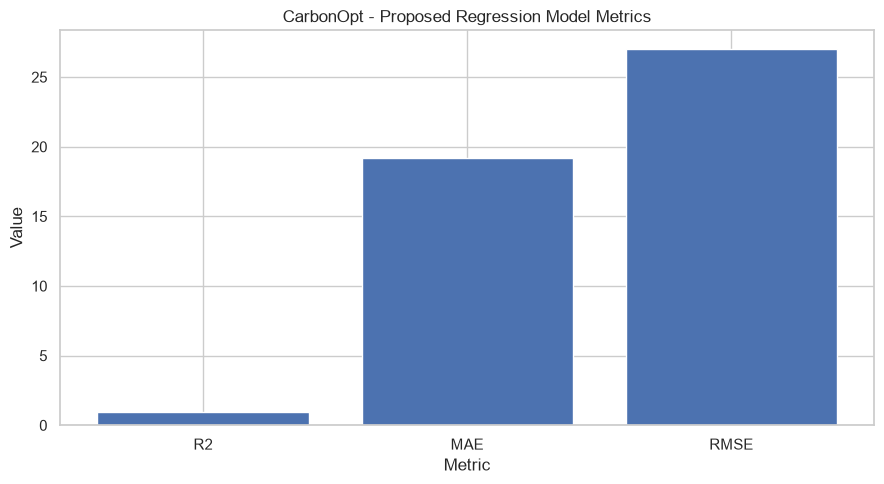

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract actual regression metrics
regression_data = comparison_df[
    (comparison_df["Task"] == "Regression") &
    (comparison_df["Metric"].isin(["R2", "MAE", "RMSE"]))
].copy()

regression_data["Value"] = pd.to_numeric(
    regression_data["Value"], errors="coerce"
)
regression_data = regression_data.dropna(subset=["Value"])

plt.figure(figsize=(9, 5))
plt.bar(regression_data["Metric"], regression_data["Value"])
plt.title("CarbonOpt - Proposed Regression Model Metrics")
plt.xlabel("Metric")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

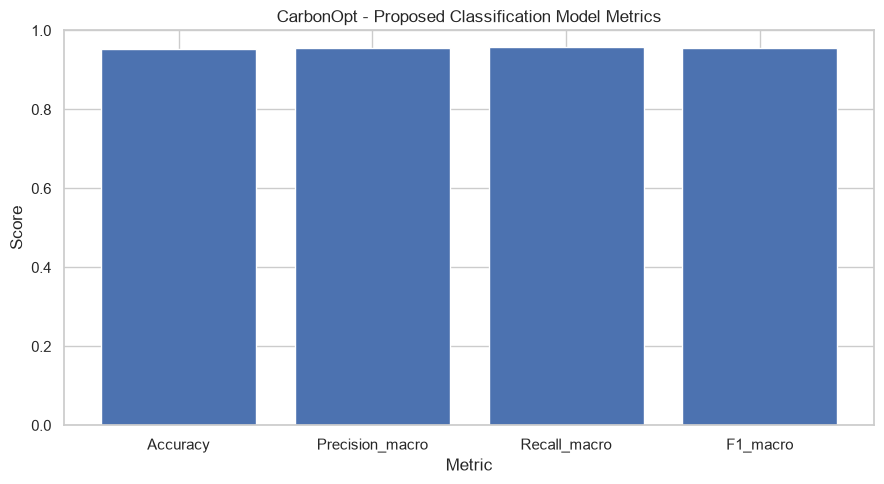

In [68]:
classification_data = comparison_df[
    (comparison_df["Task"] == "Classification") &
    (comparison_df["Metric"].isin([
        "Accuracy", "Precision_macro", "Recall_macro", "F1_macro"
    ]))
].copy()

classification_data["Value"] = pd.to_numeric(
    classification_data["Value"], errors="coerce"
)
classification_data = classification_data.dropna(subset=["Value"])

plt.figure(figsize=(9, 5))
plt.bar(classification_data["Metric"], classification_data["Value"])
plt.title("CarbonOpt - Proposed Classification Model Metrics")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

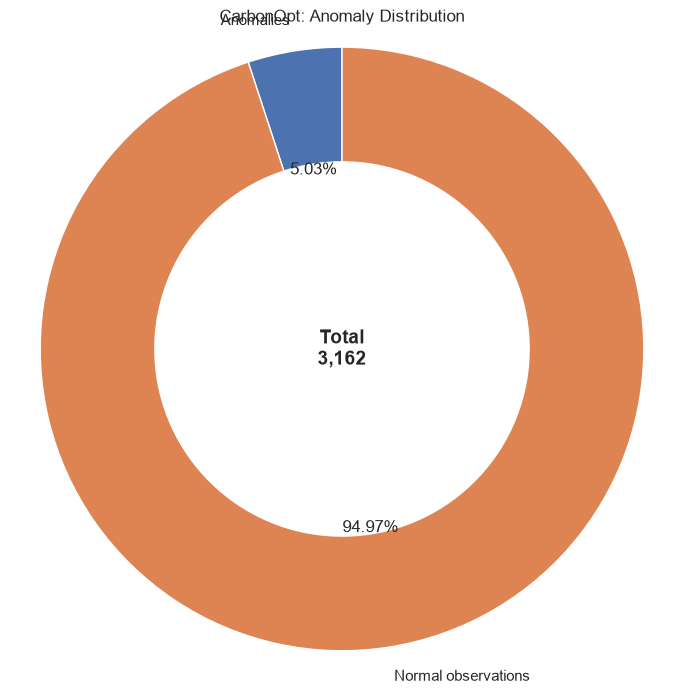

In [70]:
import matplotlib.pyplot as plt

anomaly_data = comparison_df[
    (comparison_df["Task"] == "Anomaly Detection") &
    (comparison_df["Metric"].isin([
        "Anomalies detected", "Total observations"
    ]))
].copy()

anomaly_data["Value"] = pd.to_numeric(
    anomaly_data["Value"], errors="coerce"
)
anomaly_data = anomaly_data.dropna(subset=["Value"])

counts = anomaly_data.set_index("Metric")["Value"]

anomalies = counts["Anomalies detected"]
total = counts["Total observations"]
normal = total - anomalies

fig, ax = plt.subplots(figsize=(7, 7))

wedges, texts, autotexts = ax.pie(
    [anomalies, normal],
    labels=["Anomalies", "Normal observations"],
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"width": 0.38, "edgecolor": "white"}
)

ax.text(
    0, 0,
    f"Total\n{int(total):,}",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold"
)

ax.set_title("CarbonOpt: Anomaly Distribution")
ax.axis("equal")

plt.tight_layout()
plt.show()